# Amazon Electronics Reviews EDA ratings + metadata

Notebook này phân tích toàn bộ dữ liệu trong `data/raw` của workspace:

- `Electronics.csv`: user, item, rating và Unix timestamp.
- `meta_Electronics.json` hoặc `meta_Electronics.json.gz`: title, brand, price, category và các thuộc tính sản phẩm.

Notebook dùng Spark để đọc dữ liệu lớn, chỉ đưa các bảng tổng hợp từ Spark sang Python. Các phân tích metadata được nối với ratings bằng `item_id = asin`, đảm bảo báo cáo coverage và tỷ lệ thiếu dữ liệu trong quá trình kết luận từ những item không match.


## 1. Môi trường

Dùng Python 3.9–3.12, Java 17. Có thể mở bằng Jupyter hoặc VS Code (Python + Jupyter), chọn đúng Python kernel. Với Windows, đường dẫn ở cell tiếp theo dùng chuỗi `r"C:\..."`.

Nếu chưa cài thư viện, bỏ dấu `#` ở dòng `%pip` và chạy cell, rồi restart kernel. Nếu dùng môi trường Spark có sẵn, giữ phiên bản PySpark tương thích với Spark đó. Ubuntu VM hiện có của bạn cũng chạy được notebook này.

EDA full-data có các bước shuffle và distinct nên có thể cần thời gian và đĩa trống. Không dùng Pandas để đọc toàn bộ CSV. Kết quả cùng tên trong thư mục output sẽ được ghi đè.


In [1]:
# Bỏ dấu # để cài thư viện trong kernel hiện tại:
%pip install pyspark==3.5.3 "matplotlib>=3.7,<4"
import sys, shutil
print('Python:', sys.version)
print('Java executable:', shutil.which('java'))
if shutil.which('java') is None:
    raise RuntimeError('Cần cài Java 17 và cấu hình JAVA_HOME/PATH trước khi chạy Spark.')


  Using cached pyspark-3.5.3-py2.py3-none-any.whl
  Using cached py4j-0.10.9.7-py2.py3-none-any.whl.metadata (1.5 kB)
Using cached py4j-0.10.9.7-py2.py3-none-any.whl (200 kB)

  Attempting uninstall: py4j

    Found existing installation: py4j 0.10.9.9

    Uninstalling py4j-0.10.9.9:

      Successfully uninstalled py4j-0.10.9.9

   ---------------------------------------- 0/2 [py4j]
   ---------------------------------------- 0/2 [py4j]
   ---------------------------------------- 0/2 [py4j]
   ---------------------------------------- 0/2 [py4j]
  Attempting uninstall: pyspark
   ---------------------------------------- 0/2 [py4j]
    Found existing installation: pyspark 4.0.5
   ---------------------------------------- 0/2 [py4j]
   -------------------- ------------------- 1/2 [pyspark]
    Uninstalling pyspark-4.0.5:
   -------------------- ------------------- 1/2 [pyspark]
   -------------------- ------------------- 1/2 [pyspark]
   -------------------- ------------------- 1/2 [pys

In [2]:
import sys
import pyspark

print("Python:", sys.executable)
print("PySpark:", pyspark.__version__)

Python: d:\msis406\amazon-electronics-bigdata-recommender\.venv\Scripts\python.exe
PySpark: 3.5.3


## 2. Cấu hình đường dẫn

**Chỉ cần sửa `CSV_FILE` nếu CSV không nằm cạnh notebook.** Nếu dữ liệu vẫn ở trong ZIP, hãy giải nén trước. Giữ `HAS_HEADER = False` cho CSV gốc. Nhãn `INPUT_VERSION` do bạn điền để truy vết; SHA256 của file cũng được tính tự động.


In [3]:
from pathlib import Path
from types import SimpleNamespace

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = PROJECT_ROOT / "data" / "raw"
CSV_FILE = RAW_DIR / "Electronics.csv"
METADATA_FILE = RAW_DIR / "meta_Electronics.json"
if not METADATA_FILE.is_file():
    extracted_metadata = RAW_DIR / "meta_Electronics.json" / "meta_Electronics.json"
    METADATA_FILE = extracted_metadata if extracted_metadata.is_file() else RAW_DIR / "meta_Electronics.json.gz"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "reports" / "Electronics"
HAS_HEADER = False
INPUT_VERSION = "workspace-data"

if not CSV_FILE.is_file():
    raise FileNotFoundError(f"Khong tim thay ratings CSV: {CSV_FILE.resolve()}")
if not METADATA_FILE.is_file():
    raise FileNotFoundError(f"Khong tim thay metadata JSON/JSON.GZ trong: {RAW_DIR.resolve()}")
args = SimpleNamespace(input=str(CSV_FILE.resolve()), metadata=str(METADATA_FILE.resolve()), output=str(OUTPUT_DIR), header=HAS_HEADER, input_version=INPUT_VERSION, master="local[2]", partitions=8, sample_size=10, min_time="1990-01-01", max_time=None)
print("Ratings:", CSV_FILE.resolve())
print("Metadata:", METADATA_FILE.resolve())
print("Ratings size (MiB):", round(CSV_FILE.stat().st_size / 1024**2, 2))
print("Metadata size (MiB):", round(METADATA_FILE.stat().st_size / 1024**2, 2))


Ratings: D:\msis406\amazon-electronics-bigdata-recommender\data\raw\Electronics.csv
Metadata: D:\msis406\amazon-electronics-bigdata-recommender\data\raw\meta_Electronics.json\meta_Electronics.json
Ratings size (MiB): 835.65
Metadata size (MiB): 10486.25


## 3. Import và hàm lưu kết quả/vẽ biểu đồ

Chỉ các bảng tổng hợp nhỏ được đưa từ Spark sang Python. Histogram tương tác dùng số đối tượng duy nhất; trục tung symlog giúp nhìn được nhóm hiếm lẫn nhóm phổ biến.


In [4]:
import csv
import hashlib
import json
from datetime import datetime, timezone
from pathlib import Path
from time import perf_counter

from IPython.display import display, Image, Markdown

def plots(out, rating, monthly, hist):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.dates as mdates
    import matplotlib.pyplot as plt
    from matplotlib.ticker import FuncFormatter

    figdir = out / 'figures'
    figdir.mkdir(parents=True, exist_ok=True)
    palette = {'blue': '#1769aa', 'orange': '#e07a2d', 'green': '#2a9d8f', 'red': '#c94c4c'}
    plt.rcParams.update({
        'figure.dpi': 150,
        'savefig.dpi': 200,
        'font.size': 10,
        'axes.titlesize': 13,
        'axes.labelsize': 10,
        'axes.spines.top': False,
        'axes.spines.right': False,
        'axes.grid': True,
        'grid.alpha': 0.22,
        'grid.linewidth': 0.7,
    })

    counts = [r['count'] for r in rating]
    total = sum(counts)
    fig, ax = plt.subplots(figsize=(9, 5.2))
    bars = ax.bar([r['rating'] for r in rating], counts, color=palette['blue'], width=0.68)
    ax.set_title('Rating distribution', loc='left', fontweight='bold', pad=14)
    fig.text(0.125, 0.91, f'{total:,} valid ratings from Electronics.csv',
             color='#555555', fontsize=9, va='bottom')
    ax.set_xlabel('Rating (stars)')
    ax.set_ylabel('Number of ratings')
    ax.set_xticks(range(1, 6))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value / 1e6:.1f}M' if value >= 1e6 else f'{value / 1e3:.0f}K'))
    ax.set_ylim(0, max(counts) * 1.28)
    for bar, count in zip(bars, counts):
        ax.annotate(f'{count / total:.1%}\n({count:,})',
                    xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    xytext=(0, 5), textcoords='offset points', ha='center', va='bottom', fontsize=9)
    fig.tight_layout(rect=[0, 0, 1, 0.88])
    fig.savefig(figdir / 'rating_distribution.png', bbox_inches='tight')
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(12, 5.2))
    if monthly:
        counts_by_month = {r['month']: r['count'] for r in monthly}
        y, m = map(int, min(counts_by_month).split('-'))
        last = max(counts_by_month)
        dates, values = [], []
        while f'{y:04d}-{m:02d}' <= last:
            key = f'{y:04d}-{m:02d}'
            dates.append(datetime(y, m, 1))
            values.append(counts_by_month.get(key, 0))
            y, m = (y + 1, 1) if m == 12 else (y, m + 1)
        ax.plot(dates, values, color=palette['blue'], linewidth=1.5)
        ax.fill_between(dates, values, color=palette['blue'], alpha=0.12)
        peak_index = max(range(len(values)), key=values.__getitem__)
        ax.scatter([dates[peak_index]], [values[peak_index]], color=palette['orange'], zorder=3)
        ax.annotate(f'Peak: {dates[peak_index]:%b %Y}\n{values[peak_index]:,}',
                    xy=(dates[peak_index], values[peak_index]), xytext=(8, -32),
                    textcoords='offset points', va='top', fontsize=9, color='#444444',
                    arrowprops={'arrowstyle': '->', 'color': palette['orange']})
    ax.set_title('Monthly rating activity (UTC)', loc='left', fontweight='bold', pad=14)
    fig.text(0.125, 0.91, 'Event frequency over time; not real-time ingestion speed',
             color='#555555', fontsize=9, va='bottom')
    ax.set_xlabel('Month')
    ax.set_ylabel('Number of ratings')
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value / 1e6:.1f}M' if value >= 1e6 else f'{value / 1e3:.0f}K'))
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.tick_params(axis='x', rotation=0)
    fig.tight_layout(rect=[0, 0, 1, 0.88])
    fig.savefig(figdir / 'time_activity.png', bbox_inches='tight')
    plt.close(fig)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), sharey=False)
    labels = ['1', '2-4', '5-9', '10-19', '20-49', '50-99', '100-499', '500+']
    for ax, kind, color in zip(axes, ['user', 'item'], [palette['blue'], palette['orange']]):
        lookup = {r['bin']: r['count'] for r in hist[kind]}
        values = [lookup.get(i, 0) for i in range(8)]
        bars = ax.bar(range(8), values, color=color, alpha=0.9)
        ax.set_title(f'{kind.title()} interaction frequency', loc='left', fontweight='bold', pad=12)
        ax.set_xlabel('Distinct ' + ('items per user' if kind == 'user' else 'users per item'))
        ax.set_ylabel(f'Number of {kind}s (symmetric log scale)')
        ax.set_xticks(range(8), labels, rotation=35, ha='right')
        ax.set_yscale('symlog', linthresh=1)
        ax.grid(axis='y')
        labels_on_bars = [f'{value:,}' if value else '' for value in values]
        ax.bar_label(bars, labels=labels_on_bars, padding=3, fontsize=7, rotation=90)
    fig.suptitle('Long-tail interaction structure', fontsize=15, fontweight='bold', x=0.05, ha='left', y=0.98)
    fig.text(0.05, 0.935, 'Counts use distinct user-item pairs; symmetric log scale keeps rare and popular groups visible.',
             color='#555555', fontsize=9)
    fig.tight_layout(rect=[0, 0, 1, 0.88])
    fig.savefig(figdir / 'interaction_hist.png', bbox_inches='tight')
    plt.close(fig)


## 4. Khởi tạo Spark

Mặc định local 2 core, 8 shuffle partitions, thời gian UTC. Timestamp hợp lệ nằm từ 1990-01-01 đến thời điểm bắt đầu chạy; có thể đổi cấu hình ở bước 2.


In [5]:
import os
import sys
from pathlib import Path

os.environ["HADOOP_HOME"] = r"C:\hadoop"
os.environ["PATH"] = r"C:\hadoop\bin;" + os.environ["PATH"]
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["PYSPARK_SUBMIT_ARGS"] = "--driver-memory 4g pyspark-shell"

assert Path(r"C:\hadoop\bin\winutils.exe").is_file()
assert Path(r"C:\hadoop\bin\hadoop.dll").is_file()

print("Python:", sys.executable)
print("HADOOP_HOME:", os.environ["HADOOP_HOME"])

Python: d:\msis406\amazon-electronics-bigdata-recommender\.venv\Scripts\python.exe
HADOOP_HOME: C:\hadoop


In [6]:
from datetime import datetime, timezone
from time import perf_counter

started = datetime.now(timezone.utc)
begin = perf_counter()
low = int(datetime.strptime(args.min_time, '%Y-%m-%d').replace(tzinfo=timezone.utc).timestamp())
high = int(datetime.strptime(args.max_time, '%Y-%m-%d').replace(tzinfo=timezone.utc).timestamp()) + 86399 if args.max_time else int(started.timestamp())
if low > high:
    raise ValueError('min-time must be <= max-time')
from pyspark.sql import SparkSession, functions as F, types as T
from pyspark import StorageLevel
from datetime import datetime, timezone
from time import perf_counter
spark = (SparkSession.builder.appName('AmazonRatingsEDA').master(args.master)
         .config('spark.sql.session.timeZone', 'UTC')
         .config('spark.sql.shuffle.partitions', str(args.partitions))
         .config('spark.sql.ansi.enabled', 'false').getOrCreate())
spark.sparkContext.setLogLevel('WARN')
out = Path(args.output); out.mkdir(parents=True, exist_ok=True)


## 5. Đọc CSV


In [7]:
schema = T.StructType([T.StructField(c, T.StringType()) for c in
                       ['item_raw', 'user_raw', 'rating_raw', 'timestamp_raw', '_corrupt_record']])
raw = (spark.read.schema(schema).option('header', str(args.header).lower())
       .option('mode', 'PERMISSIVE').option('columnNameOfCorruptRecord', '_corrupt_record')
       .csv(args.input).persist(StorageLevel.DISK_ONLY))
total = raw.count()
if not total:
    raise ValueError('Input contains no records')
files = sorted(raw.inputFiles())

print('Parsed records:', total)
raw.show(5, truncate=False)
raw.printSchema()
raw.unpersist()


Parsed records: 20994353
+----------+--------------+----------+-------------+---------------+
|item_raw  |user_raw      |rating_raw|timestamp_raw|_corrupt_record|
+----------+--------------+----------+-------------+---------------+
|0060009810|A1N070NS9CJQ2I|5.0       |1026864000   |NULL           |
|0060009810|A3P0KRKOBQK1KN|5.0       |1025913600   |NULL           |
|0060009810|A192HO2ICJ75VU|5.0       |1025654400   |NULL           |
|0060009810|A2T278FKFL3BLT|4.0       |1025395200   |NULL           |
|0060009810|A2ZUXVTW8RXBXW|5.0       |1025222400   |NULL           |
+----------+--------------+----------+-------------+---------------+
only showing top 5 rows

root
 |-- item_raw: string (nullable = true)
 |-- user_raw: string (nullable = true)
 |-- rating_raw: string (nullable = true)
 |-- timestamp_raw: string (nullable = true)
 |-- _corrupt_record: string (nullable = true)



DataFrame[item_raw: string, user_raw: string, rating_raw: string, timestamp_raw: string, _corrupt_record: string]

## 6. Kiểm tra null và giá trị sai


In [8]:
df = (raw.withColumn('user_id', F.trim('user_raw')).withColumn('item_id', F.trim('item_raw'))
      .withColumn('rating', F.expr('try_cast(rating_raw as double)'))
      .withColumn('timestamp_number', F.expr('try_cast(timestamp_raw as double)'))
      .withColumn('timestamp', F.expr('try_cast(timestamp_raw as bigint)')))
flags = {'malformed_csv': F.col('_corrupt_record').isNotNull()}
for name in ['user', 'item', 'rating', 'timestamp']:
    c = F.col(name + '_raw')
    flags[name + '_missing'] = c.isNull() | (F.length(F.trim(c)) == 0)
flags['rating_invalid'] = F.col('rating').isNull() | ~F.col('rating').isin(1., 2., 3., 4., 5.)
flags['timestamp_invalid'] = (F.col('timestamp').isNull() | F.col('timestamp_number').isNull()
                              | F.isnan('timestamp_number')
                              | (F.col('timestamp_number') != F.col('timestamp'))
                              | ~F.col('timestamp').between(low, high))
for name, expression in flags.items():
    df = df.withColumn(name, F.coalesce(expression, F.lit(True)))
invalid = F.lit(False)
for name in flags:
    invalid = invalid | F.col(name)
df = df.withColumn('invalid', invalid).persist(StorageLevel.DISK_ONLY)
quality = df.agg(*[F.sum(F.col(k).cast('long')).alias(k) for k in [*flags, 'invalid']]).first().asDict()
raw.unpersist()
valid = df.filter(~F.col('invalid')).select('user_id', 'item_id', 'rating', 'timestamp').persist(StorageLevel.MEMORY_AND_DISK)
n = valid.count()
df.unpersist()
if not n:
    (out / 'ratings_profile.json').write_text(json.dumps({'total_rows': total, 'quality': quality, 'error': 'No valid rows; check schema/header and time bounds'}, indent=2), encoding='utf-8')
    raise ValueError('No valid rows. See ratings_profile.json')

display(quality)
print('Valid records:', n)


{'malformed_csv': 0,
 'user_missing': 0,
 'item_missing': 0,
 'rating_missing': 0,
 'timestamp_missing': 0,
 'rating_invalid': 0,
 'timestamp_invalid': 0,
 'invalid': 0}

Valid records: 20994353


In [9]:
from pyspark.sql import functions as F

# Metadata is JSON Lines; Spark can read both the extracted JSON and .gz file.
metadata_path = Path(METADATA_FILE).resolve()
args.metadata = str(metadata_path)

metadata_raw = spark.read.json(args.metadata)
if "asin" not in metadata_raw.columns:
    raise ValueError(f"Metadata must contain 'asin'; columns: {metadata_raw.columns}")
metadata = metadata_raw.withColumnRenamed("asin", "item_id").dropDuplicates(["item_id"])
for column in ("title", "brand", "price"):
    if column not in metadata.columns:
        metadata = metadata.withColumn(column, F.lit(None).cast("string"))
if "category" not in metadata.columns:
    metadata = metadata.withColumn("category", F.array().cast("array<string>"))
metadata = metadata.withColumn(
    "category_path",
    F.when(F.col("category").cast("string").startswith("["), F.concat_ws(" > ", "category"))
     .otherwise(F.col("category").cast("string"))
)

ratings_with_metadata = valid.join(
    metadata.select("item_id", "title", "brand", "price", "category_path"),
    on="item_id", how="left"
).persist(StorageLevel.DISK_ONLY)

rating_rows = valid.count()
ratings_items = valid.select("item_id").distinct().count()
metadata_items = metadata.count()
matched = ratings_with_metadata.filter(F.col("title").isNotNull() | F.col("brand").isNotNull())
matched_rows = matched.count()
matched_items = matched.select("item_id").distinct().count()
metadata_summary = {
    "ratings_file": str(CSV_FILE.resolve()),
    "metadata_file": str(metadata_path),
    "rating_rows": rating_rows,
    "rating_items": ratings_items,
    "metadata_items": metadata_items,
    "matched_rating_rows": matched_rows,
    "row_match_rate": matched_rows / rating_rows if rating_rows else 0,
    "item_match_rate": matched_items / ratings_items if ratings_items else 0,
}
print("Ratings file:", CSV_FILE.resolve())
print("Metadata file:", metadata_path)
print(metadata_summary)

metadata_quality = ratings_with_metadata.agg(
    F.count("*").alias("rating_rows"),
    F.sum(F.col("title").isNull().cast("long")).alias("missing_title_rows"),
    F.sum(F.col("brand").isNull().cast("long")).alias("missing_brand_rows"),
    F.sum(F.col("price").isNull().cast("long")).alias("missing_price_rows"),
    F.sum(F.col("category_path").isNull().cast("long")).alias("missing_category_rows"),
)
metadata_quality.show(truncate=False)

top_items_metadata = (ratings_with_metadata
    .groupBy("item_id", "title", "brand", "price", "category_path")
    .agg(F.count("*").alias("ratings"), F.avg("rating").alias("mean_rating"), F.stddev_pop("rating").alias("rating_std"))
    .orderBy(F.desc("ratings"), F.asc("item_id")))
print("Top 20 items with metadata")
top_items_metadata.limit(20).show(truncate=80)

brand_summary = (ratings_with_metadata.filter(F.col("brand").isNotNull())
    .groupBy("brand")
    .agg(F.countDistinct("item_id").alias("items"), F.count("*").alias("ratings"), F.avg("rating").alias("mean_rating"))
    .orderBy(F.desc("ratings")))
print("Top 20 brands by rating volume")
brand_summary.limit(20).show(truncate=False)

category_summary = (ratings_with_metadata.filter(F.col("category_path").isNotNull())
    .groupBy("category_path")
    .agg(F.countDistinct("item_id").alias("items"), F.count("*").alias("ratings"), F.avg("rating").alias("mean_rating"))
    .orderBy(F.desc("ratings")))
print("Top 20 categories by rating volume")
category_summary.limit(20).show(truncate=100)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for frame, filename in ((brand_summary.limit(100), "top100_brands_metadata.csv"), (category_summary.limit(100), "top100_categories_metadata.csv"), (top_items_metadata.limit(100), "top100_items_with_metadata.csv")):
    frame.toPandas().to_csv(OUTPUT_DIR / filename, index=False)
import json
(OUTPUT_DIR / "metadata_join_summary.json").write_text(json.dumps(metadata_summary, indent=2), encoding="utf-8")
print("Saved metadata tables to:", OUTPUT_DIR.resolve())
ratings_with_metadata.unpersist()
metadata.unpersist()
metadata_raw.unpersist()


Ratings file: D:\msis406\amazon-electronics-bigdata-recommender\data\raw\Electronics.csv
Metadata file: D:\msis406\amazon-electronics-bigdata-recommender\data\raw\meta_Electronics.json\meta_Electronics.json
{'ratings_file': 'D:\\msis406\\amazon-electronics-bigdata-recommender\\data\\raw\\Electronics.csv', 'metadata_file': 'D:\\msis406\\amazon-electronics-bigdata-recommender\\data\\raw\\meta_Electronics.json\\meta_Electronics.json', 'rating_rows': 20994353, 'rating_items': 756489, 'metadata_items': 756077, 'matched_rating_rows': 20976794, 'row_match_rate': 0.9991636322395837, 'item_match_rate': 0.9994342283893091}
+-----------+------------------+------------------+------------------+---------------------+
|rating_rows|missing_title_rows|missing_brand_rows|missing_price_rows|missing_category_rows|
+-----------+------------------+------------------+------------------+---------------------+
|20994353   |17559             |17559             |17559             |17559                |
+------

DataFrame[also_buy: array<string>, also_view: array<string>, asin: string, brand: string, category: array<string>, date: string, description: array<string>, details: struct<
    Item Weight: 
    :string,
    Package Dimensions: 
    :string,
    Product Dimensions: 
    :string, Date first listed on Amazon::string, UNSPSC Code::string,ASIN::string,ASIN: :string,Batteries:string,Cards::string,Discontinued by manufacturer::string,Domestic Shipping: :string,Downloading::string,Electronics::string,Hardcover::string,ISBN-10::string,ISBN-13::string,International Shipping: :string,Item model number::string,Language::string,Note::string,Paperback::string,Perfect Paperback::string,Publisher::string,Series::string,Shipping Advisory::string,Shipping Weight::string,Shipping: :string,UPC::string>, feature: array<string>, fit: string, imageURL: array<string>, imageURLHighRes: array<string>, main_cat: string, price: string, rank: string, similar_item: string, tech1: string, tech2: string, title: str

## 6b. EDA metadata chuyên sâu

Phân tích metadata ở cấp độ sâu (không lập theo số rating), gồm các yếu tố như: các trường dữ liệu, phong cách nội dung, phần bộ giá, cấu trúc category, các tập trung thương hiệu và liên hệ giữa chất lượng metadata với rating. Các bảng được xuất ra `outputs/reports/Electronics/metadata_deep_eda/`.


In [10]:
from functools import reduce
from operator import add
import csv

metadata_deep_dir = OUTPUT_DIR / "metadata_deep_eda"
metadata_deep_dir.mkdir(parents=True, exist_ok=True)

# Reuse the Spark DataFrames created above; metadata fields are evaluated per item.
array_fields = ["description", "feature", "imageURL", "imageURLHighRes", "also_buy", "also_view"]
text_fields = ["title", "brand", "price", "main_cat", "rank", "tech1", "tech2", "fit", "similar_item"]
for column in array_fields:
    if column not in metadata.columns:
        metadata = metadata.withColumn(column, F.array().cast("array<string>"))
for column in text_fields:
    if column not in metadata.columns:
        metadata = metadata.withColumn(column, F.lit(None).cast("string"))

empty_text = lambda column: F.col(column).isNull() | (F.length(F.trim(F.col(column).cast("string"))) == 0)
deep_required_columns = ["item_id", "category"] + text_fields + array_fields
metadata_features = metadata.select(*deep_required_columns)
for column in text_fields:
    metadata_features = metadata_features.withColumn(f"has_{column}", (~empty_text(column)).cast("long"))
for column in array_fields:
    metadata_features = metadata_features.withColumn(f"{column}_count", F.coalesce(F.size(F.col(column)), F.lit(0)))

metadata_features = (
    metadata_features
    .withColumn("title_length", F.when(~empty_text("title"), F.length(F.trim("title"))).otherwise(0))
    .withColumn("description_count", F.coalesce(F.size("description"), F.lit(0)))
    .withColumn("feature_count", F.coalesce(F.size("feature"), F.lit(0)))
)
# Prefer high-resolution images, falling back to regular image URLs when absent.
metadata_features = metadata_features.withColumn(
    "image_count",
    F.when(F.size("imageURLHighRes") > 0, F.size("imageURLHighRes"))
     .otherwise(F.coalesce(F.size("imageURL"), F.lit(0)))
)
metadata_features = metadata_features.withColumn(
    "price_number",
    F.regexp_extract(F.col("price").cast("string"), r"([0-9]+(?:\.[0-9]+)?)", 1).cast("double")
)
metadata_features = metadata_features.withColumn(
    "category_depth",
    F.when(F.size("category") > 0, F.size("category")).otherwise(0)
).withColumn(
    "top_category",
    F.when(F.size("category") > 0, F.element_at("category", 1)).otherwise(F.lit("<missing>"))
).withColumn(
    "leaf_category",
    F.when(F.size("category") > 0, F.element_at("category", -1)).otherwise(F.lit("<missing>"))
)
metadata_features = metadata_features.select(
    "item_id", *text_fields,
    *[f"has_{column}" for column in text_fields],
    *[f"{column}_count" for column in array_fields],
    "title_length", "image_count", "price_number", "category_depth", "top_category", "leaf_category",
)

completeness_fields = [f"has_{column}" for column in text_fields] + [f"{column}_count" for column in array_fields]
metadata_features = metadata_features.withColumn(
    "metadata_completeness_score",
    reduce(add, [F.col(f"has_{column}") for column in text_fields]) / F.lit(len(text_fields))
).persist(StorageLevel.DISK_ONLY)

# Product-level completeness and structural distributions. One aggregation avoids
# launching a separate full metadata scan for every field.
quality_aggregates = [F.count("*").alias("items")]
for column in text_fields:
    quality_aggregates.extend([
        F.sum(F.col(f"has_{column}")).alias(f"{column}_present"),
        F.avg(F.col(f"has_{column}")).alias(f"{column}_rate"),
    ])
for column in array_fields:
    quality_aggregates.extend([
        F.sum((F.col(f"{column}_count") > 0).cast("long")).alias(f"{column}_present"),
        F.avg((F.col(f"{column}_count") > 0).cast("double")).alias(f"{column}_rate"),
    ])
quality_numeric_columns = [f"has_{column}" for column in text_fields] + [f"{column}_count" for column in array_fields]
quality_values = metadata_features.select(*quality_numeric_columns).agg(*quality_aggregates).first().asDict()
field_quality_rows = []
for column in text_fields + array_fields:
    field_quality_rows.append({
        "field": column,
        "items": quality_values["items"],
        "present_items": quality_values[f"{column}_present"],
        "presence_rate": quality_values[f"{column}_rate"],
    })

price_stats = metadata_features.filter(F.col("price_number").isNotNull() & (F.col("price_number") >= 0)).agg(
    F.count("*").alias("priced_items"),
    F.min("price_number").alias("min_price"),
    F.max("price_number").alias("max_price"),
    F.avg("price_number").alias("mean_price"),
    F.expr("percentile_approx(price_number, array(0.25, 0.5, 0.75, 0.95, 0.99), 10000)").alias("price_quantiles"),
).first().asDict()
price_stats["price_quantiles"] = dict(zip(["p25", "p50", "p75", "p95", "p99"], price_stats["price_quantiles"] or []))

content_stats = metadata_features.agg(
    F.count("*").alias("metadata_items"),
    F.avg("title_length").alias("mean_title_length"),
    F.expr("percentile_approx(title_length, array(0.5, 0.9, 0.99), 10000)").alias("title_length_quantiles"),
    F.avg("description_count").alias("mean_description_count"),
    F.avg("feature_count").alias("mean_feature_count"),
    F.avg("image_count").alias("mean_image_count"),
    F.avg("also_buy_count").alias("mean_also_buy_count"),
    F.avg("also_view_count").alias("mean_also_view_count"),
).first().asDict()
content_stats["title_length_quantiles"] = dict(zip(["p50", "p90", "p99"], content_stats["title_length_quantiles"] or []))

brand_summary_deep = (metadata_features
    .withColumn("brand_clean", F.when(empty_text("brand"), F.lit("<missing>"))
                .otherwise(F.lower(F.regexp_replace(F.trim("brand"), r"\s+", " "))))
    .groupBy("brand_clean")
    .agg(F.count("*").alias("items"), F.avg("metadata_completeness_score").alias("mean_completeness"))
    .orderBy(F.desc("items")))
category_summary_deep = (metadata_features
    .groupBy("top_category")
    .agg(F.count("*").alias("items"), F.avg("category_depth").alias("mean_depth"), F.avg("metadata_completeness_score").alias("mean_completeness"))
    .orderBy(F.desc("items")))
category_depth_summary = (metadata_features.groupBy("category_depth").count().orderBy("category_depth"))

metadata_rating_features = metadata_features.select("item_id", "metadata_completeness_score", "title_length", "price_number", "category_depth", "image_count")
item_rating_summary = (valid.groupBy("item_id")
    .agg(F.count("*").alias("ratings"), F.avg("rating").alias("mean_rating"))
    .join(metadata_rating_features, "item_id", "left"))
correlation_features = ["metadata_completeness_score", "title_length", "price_number", "category_depth", "image_count"]
correlation_values = item_rating_summary.agg(*[
    F.corr(feature, "mean_rating").alias(feature) for feature in correlation_features
]).first().asDict()
correlation_rows = [
    {"feature": feature, "pearson_correlation_with_mean_rating": correlation_values[feature]}
    for feature in correlation_features
]

# Rating coverage and metadata completeness use one aggregation per DataFrame.
rated_item_ids = valid.select("item_id").distinct().persist(StorageLevel.DISK_ONLY)
rated_item_count = rated_item_ids.count()
matched_item_count = metadata_features.join(rated_item_ids, "item_id", "left_semi").count()
metadata_counts = metadata_features.agg(
    F.count("*").alias("metadata_items"),
    F.sum(F.col("price_number").isNotNull().cast("long")).alias("metadata_items_with_price"),
    F.sum((~empty_text("title")).cast("long")).alias("metadata_items_with_nonempty_title"),
    F.sum((~empty_text("brand")).cast("long")).alias("metadata_items_with_nonempty_brand"),
    F.sum((F.col("category_depth") > 0).cast("long")).alias("metadata_items_with_nonempty_category"),
).first().asDict()
metadata_summary_deep = {
    **metadata_counts,
    "rated_items": rated_item_count,
    "rated_items_with_metadata": matched_item_count,
    "rated_item_match_rate": matched_item_count / rated_item_count if rated_item_count else 0,
    "price": price_stats,
    "content": content_stats,
}
rated_item_ids.unpersist()
metadata_features.unpersist()

for rows, filename in [
    (field_quality_rows, "field_quality.csv"),
    ([r.asDict() for r in category_depth_summary.collect()], "category_depth.csv"),
    ([r.asDict() for r in category_summary_deep.limit(100).collect()], "top100_top_categories.csv"),
    ([r.asDict() for r in brand_summary_deep.limit(100).collect()], "top100_brands_by_item_count.csv"),
    (correlation_rows, "metadata_rating_correlations.csv"),
]:
    output_path = metadata_deep_dir / filename
    with output_path.open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(
            handle,
            fieldnames=sorted({key for row in rows for key in row}),
            extrasaction="ignore",
        )
        writer.writeheader()
        writer.writerows(rows)
(metadata_deep_dir / "metadata_deep_summary.json").write_text(json.dumps(metadata_summary_deep, ensure_ascii=False, indent=2, default=str), encoding="utf-8")

print(json.dumps(metadata_summary_deep, ensure_ascii=False, indent=2, default=str))
print("Saved deep metadata EDA to:", metadata_deep_dir.resolve())


{
  "metadata_items": 756077,
  "metadata_items_with_price": 300135,
  "metadata_items_with_nonempty_title": 756063,
  "metadata_items_with_nonempty_brand": 750731,
  "metadata_items_with_nonempty_category": 756077,
  "rated_items": 756489,
  "rated_items_with_metadata": 756061,
  "rated_item_match_rate": 0.9994342283893091,
  "price": {
    "priced_items": 300135,
    "min_price": 0.01,
    "max_price": 999.99,
    "mean_price": 25.773334965928832,
    "price_quantiles": {
      "p25": 4.99,
      "p50": 9.95,
      "p75": 18.75,
      "p95": 90.1,
      "p99": 349.99
    }
  },
  "content": {
    "metadata_items": 756077,
    "mean_title_length": 102.5143126956646,
    "title_length_quantiles": {
      "p50": 86,
      "p90": 183,
      "p99": 314
    },
    "mean_description_count": 1.5518538455739297,
    "mean_feature_count": 3.926875172766795,
    "mean_image_count": 2.779464260915224,
    "mean_also_buy_count": 2.486402839922389,
    "mean_also_view_count": 6.5976137351089905
  

## 6c. Biểu đồ insight từ metadata

Các biểu đồ đọc các bảng tổng hợp đã lưu ở `metadata_deep_eda`, không chạy lại Spark. Chúng tập trung vào độ đầy đủ metadata, mức tập trung brand/category, cấu trúc category, giá và mối liên hệ mô tả với rating.


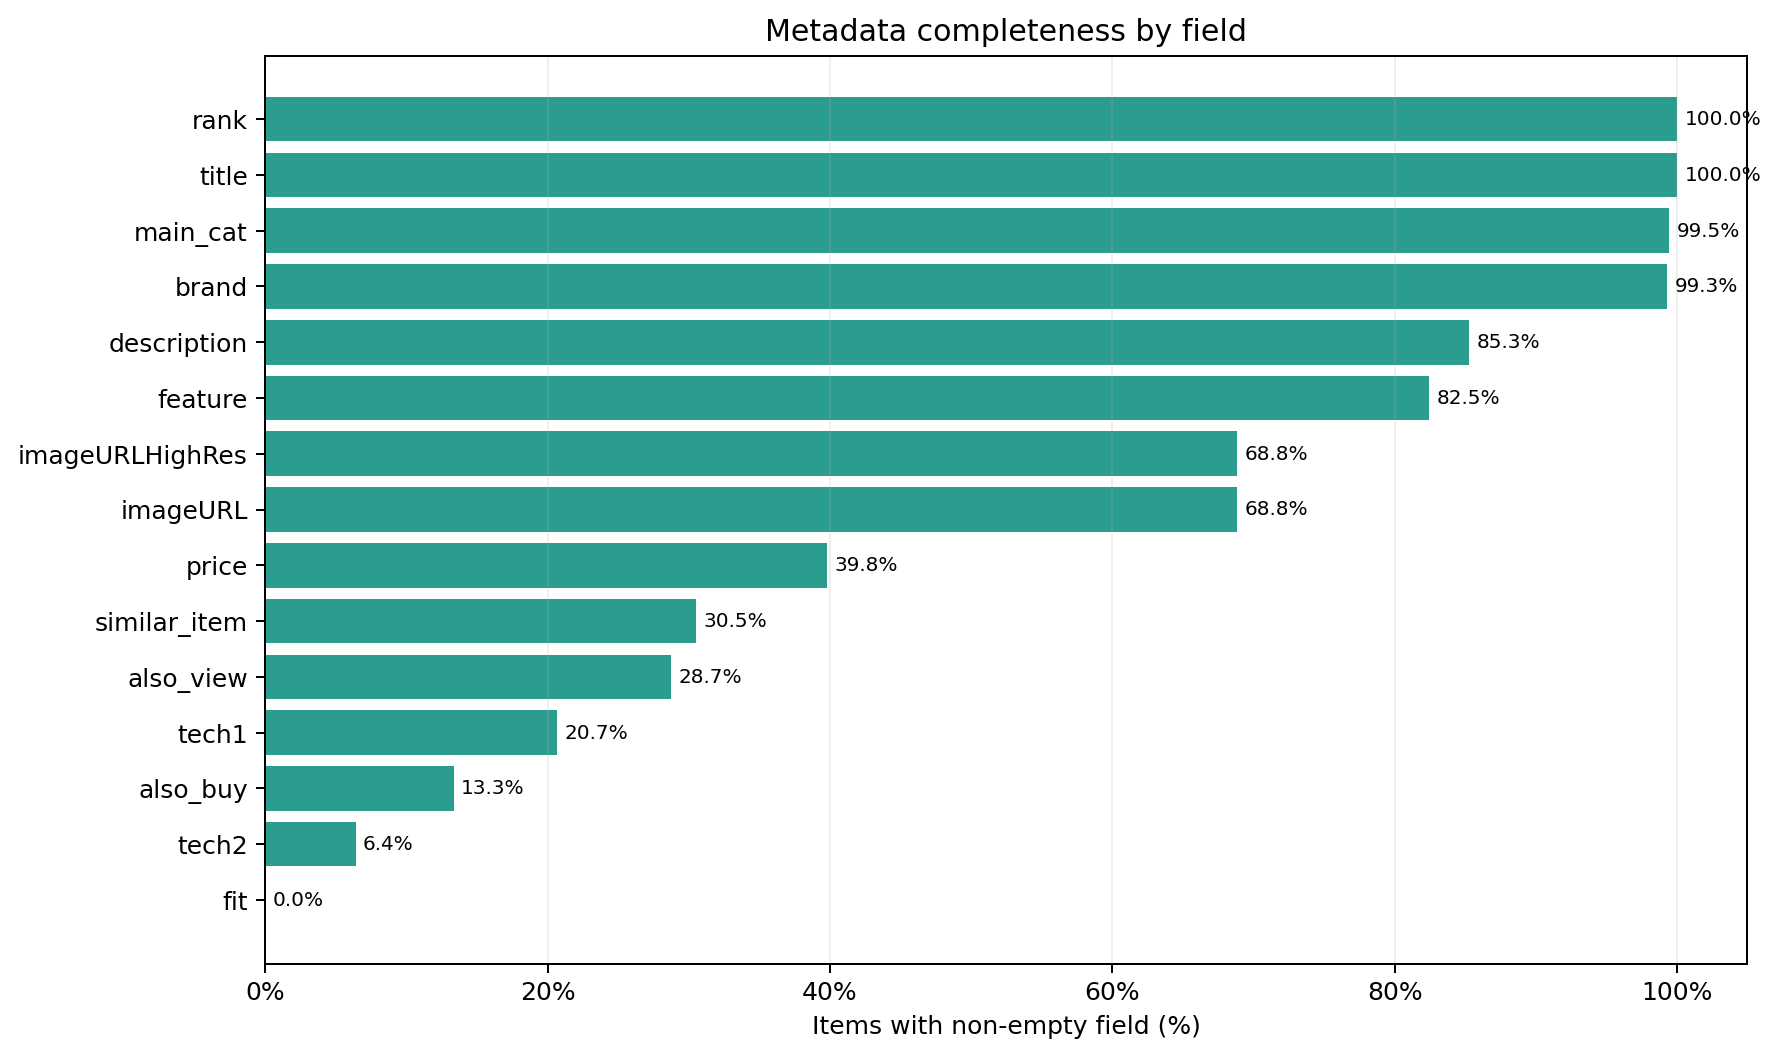

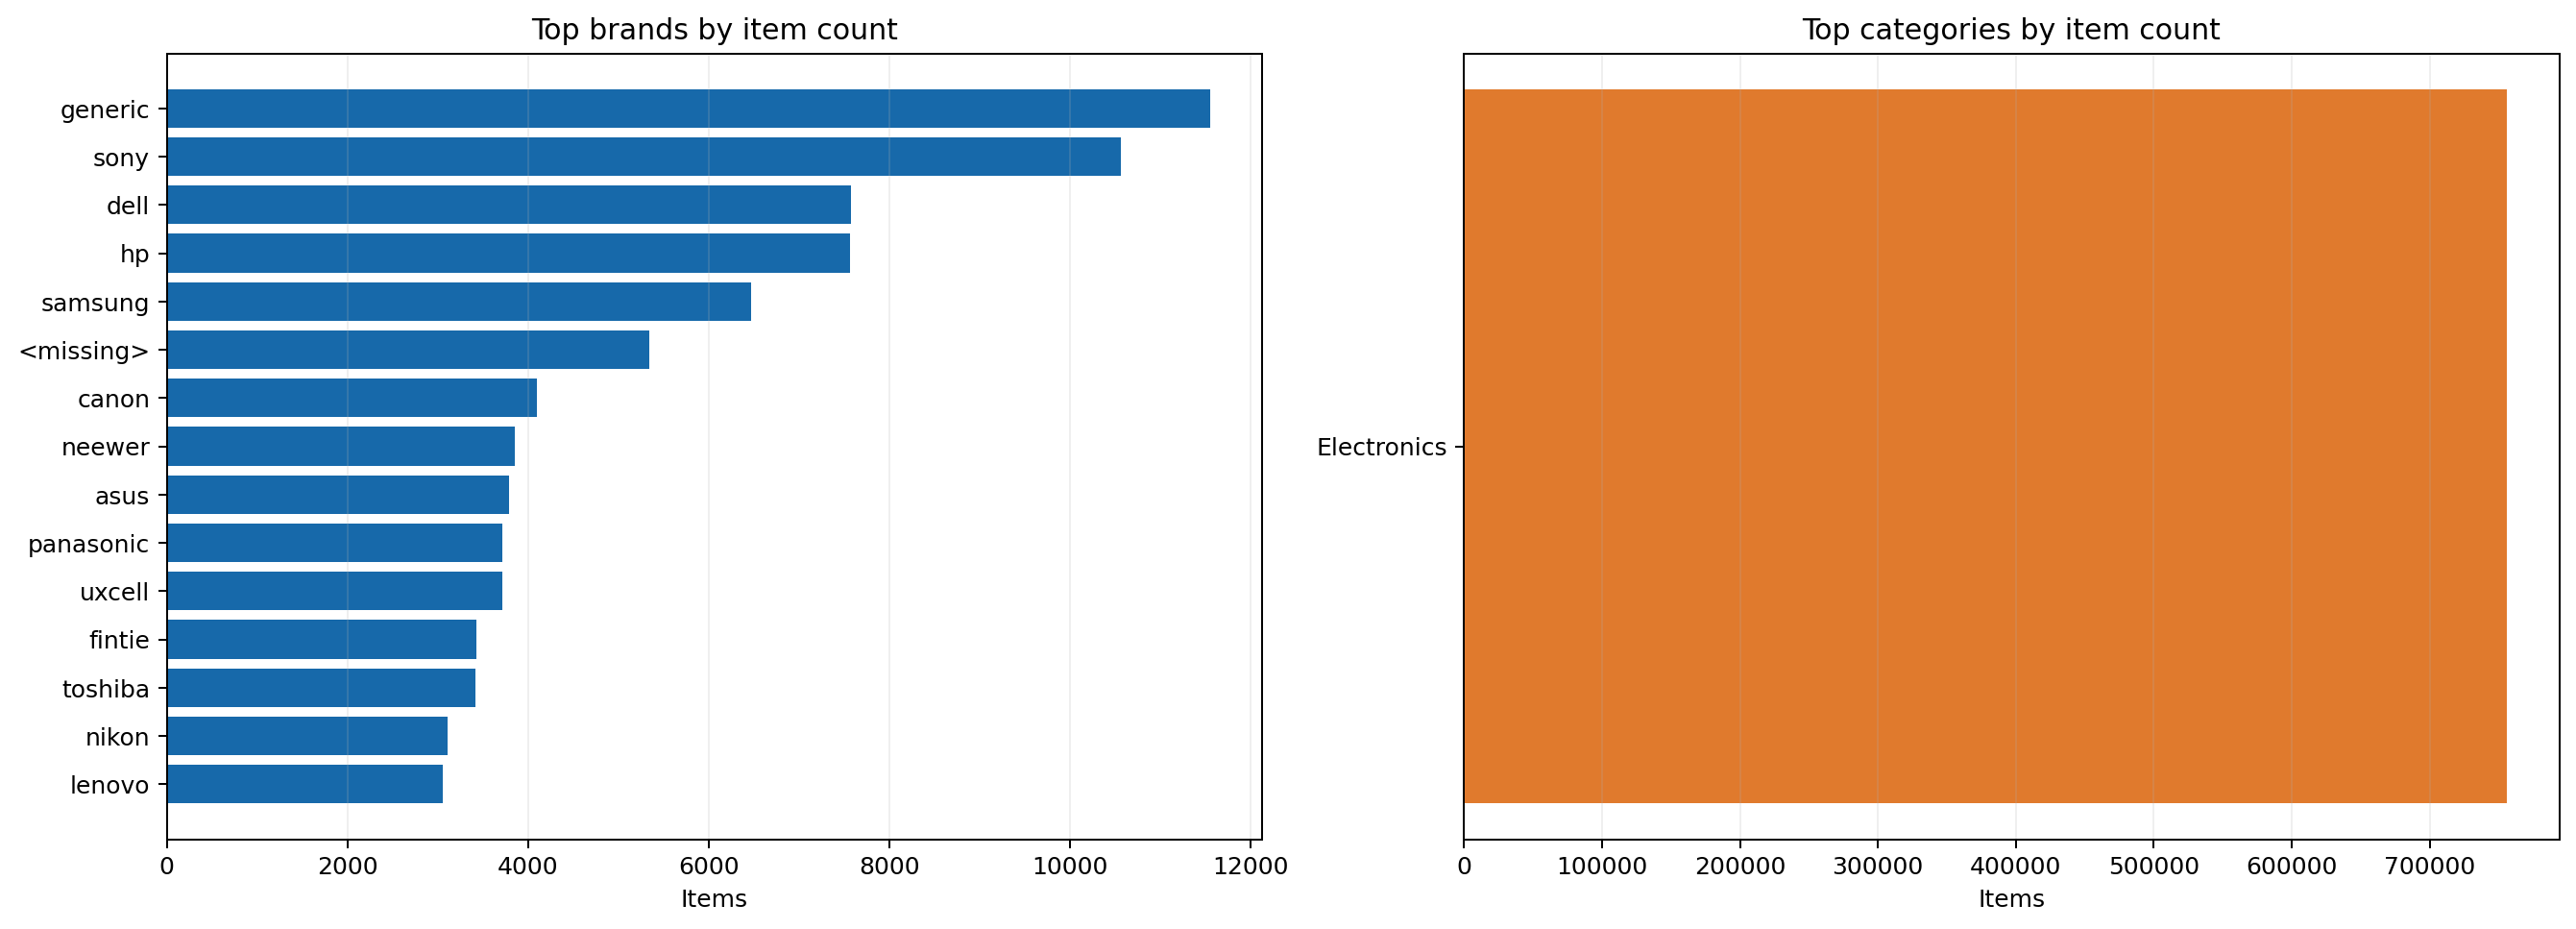

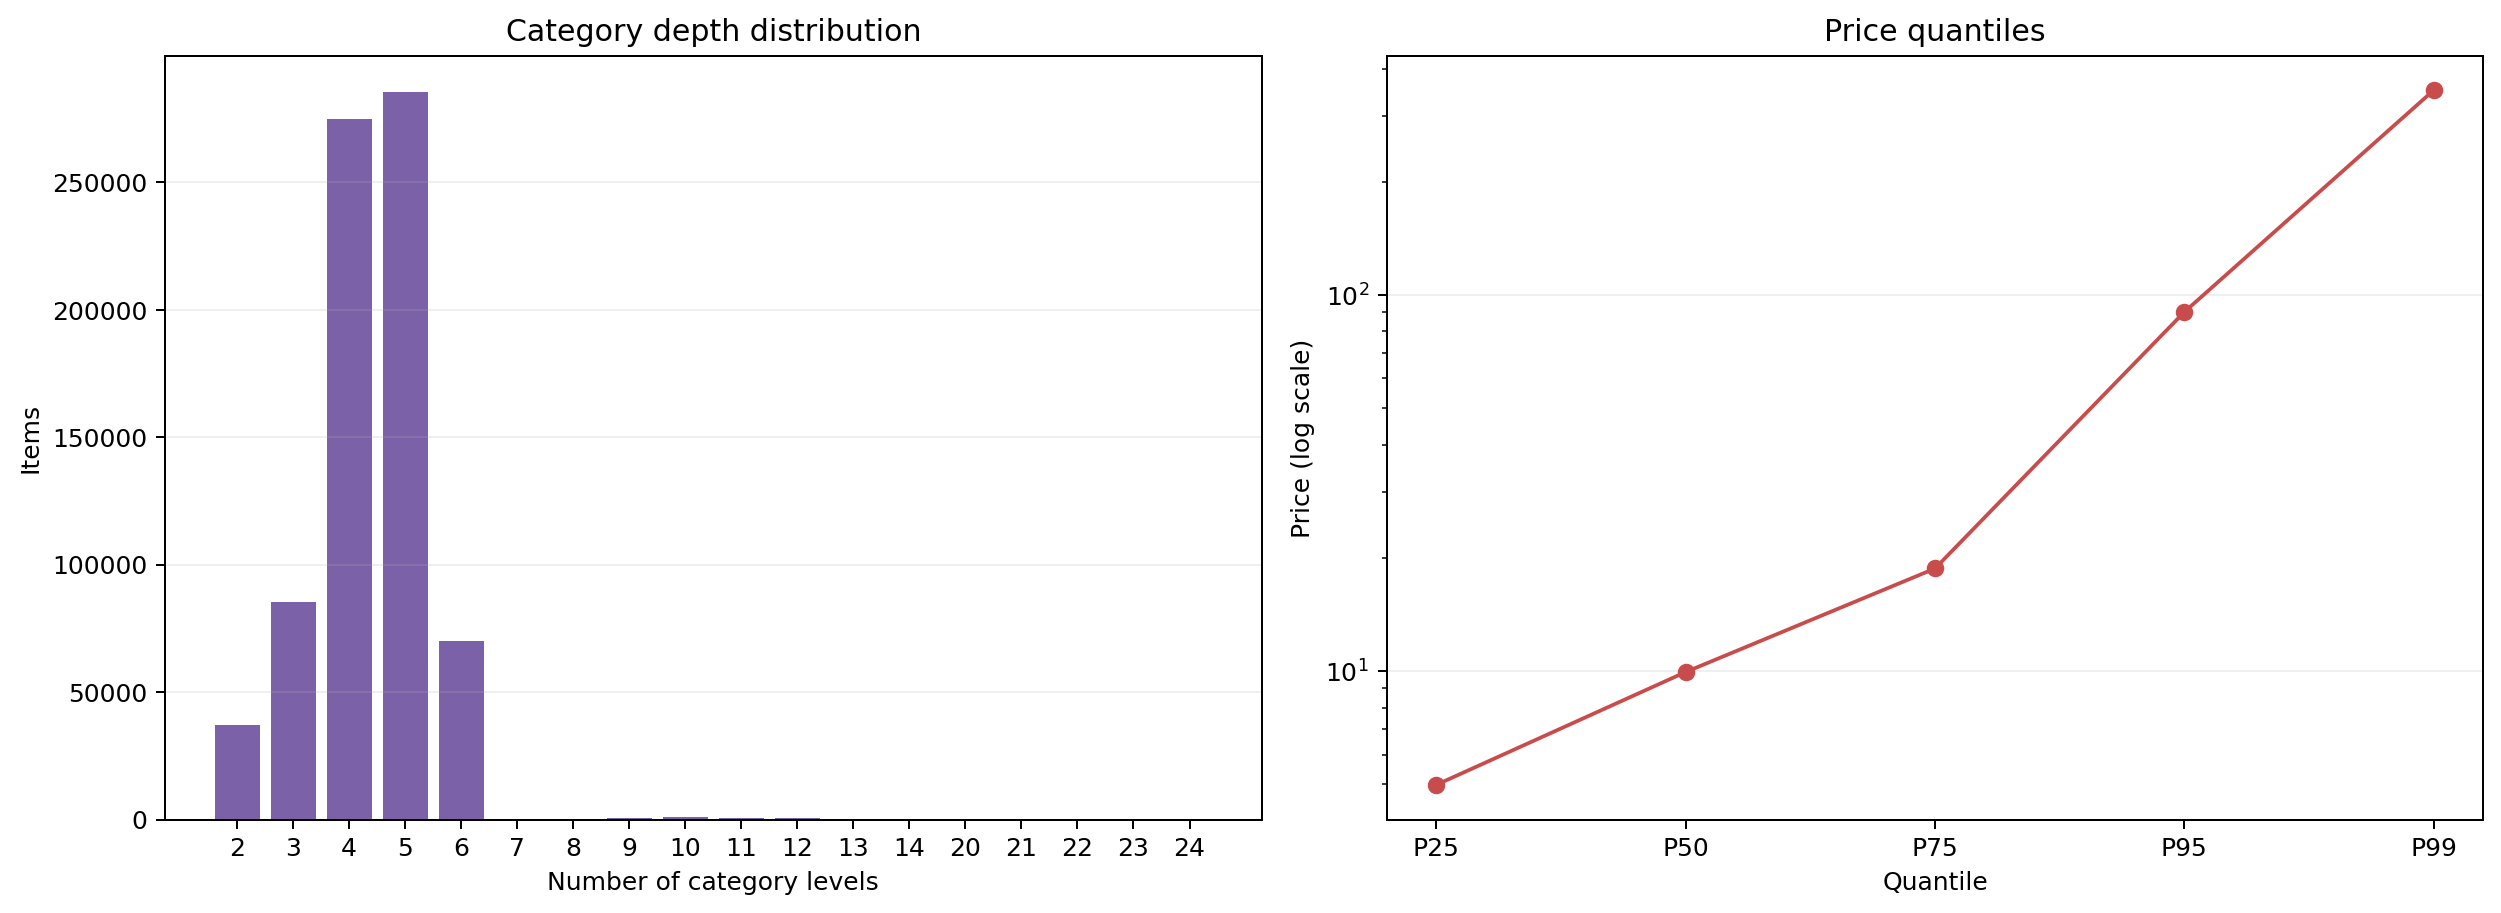

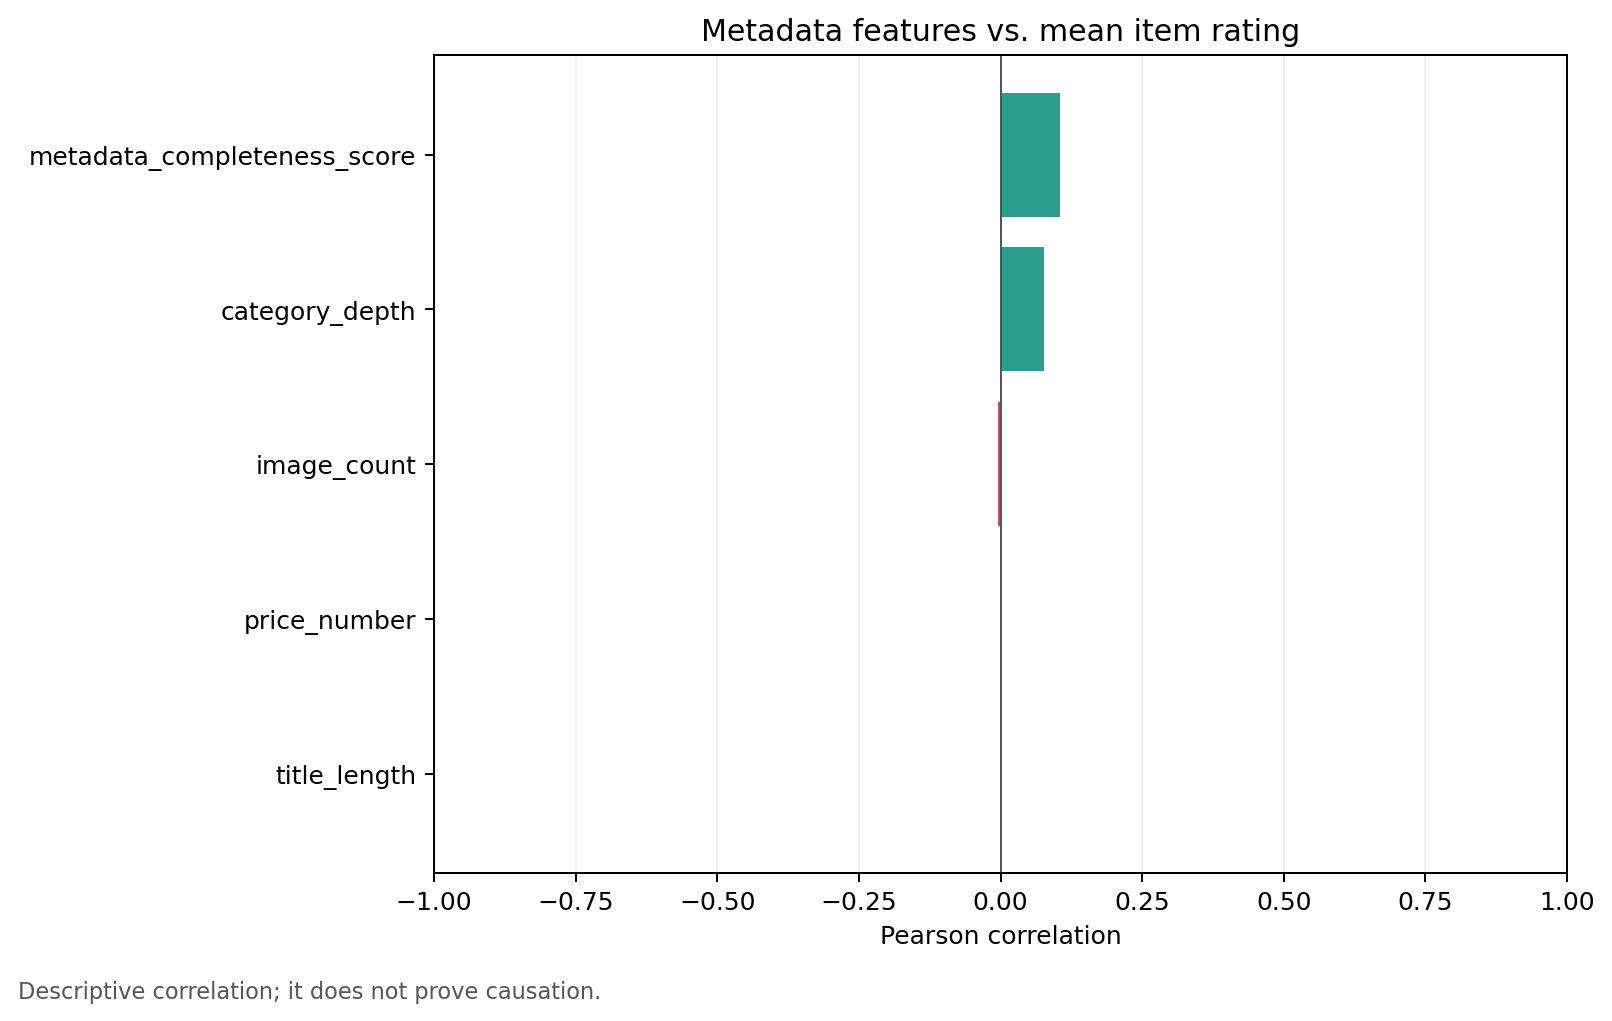

In [11]:
import csv
import json
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

def read_metadata_csv(path):
    with path.open(newline="", encoding="utf-8") as handle:
        return list(csv.DictReader(handle))

def save_metadata_figure(fig, filename):
    fig.tight_layout()
    path = metadata_deep_dir / filename
    fig.savefig(path, dpi=180, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(path)))

field_rows = read_metadata_csv(metadata_deep_dir / "field_quality.csv")
depth_rows = read_metadata_csv(metadata_deep_dir / "category_depth.csv")
brand_rows = read_metadata_csv(metadata_deep_dir / "top100_brands_by_item_count.csv")
category_rows = read_metadata_csv(metadata_deep_dir / "top100_top_categories.csv")
correlation_rows = read_metadata_csv(metadata_deep_dir / "metadata_rating_correlations.csv")
with (metadata_deep_dir / "metadata_deep_summary.json").open(encoding="utf-8") as handle:
    deep_summary = json.load(handle)

field_rows = sorted(field_rows, key=lambda row: float(row["presence_rate"]))
fig, ax = plt.subplots(figsize=(10, 6))
values = [100 * float(row["presence_rate"]) for row in field_rows]
bars = ax.barh([row["field"] for row in field_rows], values, color="#2a9d8f")
ax.bar_label(bars, labels=[f"{value:.1f}%" for value in values], padding=3, fontsize=8)
ax.set(xlim=(0, 105), xlabel="Items with non-empty field (%)", title="Metadata completeness by field")
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.grid(axis="x", alpha=0.2)
save_metadata_figure(fig, "metadata_field_completeness.png")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
top_brands = list(reversed(brand_rows[:15]))
axes[0].barh([row["brand_clean"][:28] for row in top_brands], [int(row["items"]) for row in top_brands], color="#1769aa")
axes[0].set(title="Top brands by item count", xlabel="Items")
top_categories = list(reversed(category_rows[:15]))
axes[1].barh([row["top_category"][:32] for row in top_categories], [int(row["items"]) for row in top_categories], color="#e07a2d")
axes[1].set(title="Top categories by item count", xlabel="Items")
for axis in axes:
    axis.grid(axis="x", alpha=0.2)
save_metadata_figure(fig, "metadata_brand_category_concentration.png")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
axes[0].bar([row["category_depth"] for row in depth_rows], [int(row["count"]) for row in depth_rows], color="#7b61a8")
axes[0].set(title="Category depth distribution", xlabel="Number of category levels", ylabel="Items")
axes[0].grid(axis="y", alpha=0.2)
quantiles = deep_summary.get("price", {}).get("price_quantiles", {})
quantile_keys = [key for key in ["p25", "p50", "p75", "p95", "p99"] if key in quantiles]
axes[1].plot([key.upper() for key in quantile_keys], [quantiles[key] for key in quantile_keys], "o-", color="#c94c4c")
axes[1].set(title="Price quantiles", xlabel="Quantile", ylabel="Price (log scale)", yscale="log")
axes[1].grid(axis="y", alpha=0.2)
save_metadata_figure(fig, "metadata_structure_and_price.png")

correlation_rows = sorted(correlation_rows, key=lambda row: abs(float(row["pearson_correlation_with_mean_rating"] or 0)))
fig, ax = plt.subplots(figsize=(9, 5.5))
corr_values = [float(row["pearson_correlation_with_mean_rating"] or 0) for row in correlation_rows]
ax.barh([row["feature"] for row in correlation_rows], corr_values,
        color=["#2a9d8f" if value >= 0 else "#c94c4c" for value in corr_values])
ax.axvline(0, color="#555555", linewidth=0.8)
ax.set(title="Metadata features vs. mean item rating", xlabel="Pearson correlation", xlim=(-1, 1))
ax.grid(axis="x", alpha=0.2)
fig.text(0.01, -0.02, "Descriptive correlation; it does not prove causation.", fontsize=9, color="#555555")
save_metadata_figure(fig, "metadata_rating_correlations.png")


## 7. Thống kê và độ thưa


In [12]:
stats = valid.agg(F.min('timestamp').alias('min_time'), F.max('timestamp').alias('max_time'),
                  F.avg('rating').alias('mean_rating'), F.stddev_pop('rating').alias('std_rating')).first().asDict()
exact_unique_rows = valid.dropDuplicates().count()
pairs = valid.select('user_id', 'item_id').distinct().persist(StorageLevel.MEMORY_AND_DISK)
unique_pairs = pairs.count()
activity = {kind: pairs.groupBy(kind + '_id').count().persist(StorageLevel.MEMORY_AND_DISK) for kind in ['user', 'item']}
entities = {kind: frame.count() for kind, frame in activity.items()}

print('Users:', entities['user'], '| Items:', entities['item'])
print('Unique pairs:', unique_pairs)
print('Exact duplicate excess:', n - exact_unique_rows)
print('Sparsity:', 1 - unique_pairs / (entities['user'] * entities['item']))


Users: 9838676 | Items: 756489
Unique pairs: 20553480
Exact duplicate excess: 426262
Sparsity: 0.9999972384933816


## 8. Phân bố rating và hoạt động theo thời gian


In [13]:
distribution = {int(r['rating']): r['count'] for r in valid.groupBy('rating').count().collect()}
rating = [{'rating': k, 'count': distribution.get(k, 0), 'fraction': distribution.get(k, 0) / n} for k in range(1, 6)]
dated = valid.withColumn('review_date', F.to_date(F.from_unixtime('timestamp')))
monthly = [r.asDict() for r in dated.groupBy(F.date_format('review_date', 'yyyy-MM').alias('month')).count().orderBy('month').collect()]
yearly = [r.asDict() for r in dated.groupBy(F.year('review_date').alias('year')).count().orderBy('year').collect()]

display(rating)
display(yearly)


[{'rating': 1, 'count': 2415650, 'fraction': 0.1150618930719132},
 {'rating': 2, 'count': 1139589, 'fraction': 0.054280739206395166},
 {'rating': 3, 'count': 1529818, 'fraction': 0.07286807076169483},
 {'rating': 4, 'count': 3306379, 'fraction': 0.157488968581218},
 {'rating': 5, 'count': 12602917, 'fraction': 0.6003003283787788}]

[{'year': 1997, 'count': 1},
 {'year': 1998, 'count': 2},
 {'year': 1999, 'count': 1074},
 {'year': 2000, 'count': 7981},
 {'year': 2001, 'count': 12905},
 {'year': 2002, 'count': 16818},
 {'year': 2003, 'count': 21075},
 {'year': 2004, 'count': 29009},
 {'year': 2005, 'count': 52553},
 {'year': 2006, 'count': 83028},
 {'year': 2007, 'count': 187484},
 {'year': 2008, 'count': 267963},
 {'year': 2009, 'count': 347353},
 {'year': 2010, 'count': 379921},
 {'year': 2011, 'count': 555716},
 {'year': 2012, 'count': 890182},
 {'year': 2013, 'count': 1907898},
 {'year': 2014, 'count': 2923559},
 {'year': 2015, 'count': 4212673},
 {'year': 2016, 'count': 4446409},
 {'year': 2017, 'count': 3158123},
 {'year': 2018, 'count': 1492626}]

## 9. Phân bố tương tác user/item


In [14]:
hist, activity_stats = {}, {}
for kind, frame in activity.items():
    c = F.col('count')
    bucket = (F.when(c == 1, 0).when(c < 5, 1).when(c < 10, 2).when(c < 20, 3)
              .when(c < 50, 4).when(c < 100, 5).when(c < 500, 6).otherwise(7))
    hist[kind] = [r.asDict() for r in frame.select(bucket.alias('bin')).groupBy('bin').count().orderBy('bin').collect()]
    s = frame.agg(F.min('count').alias('min'), F.max('count').alias('max'), F.avg('count').alias('mean'),
                  F.sum((c == 1).cast('long')).alias('single_interaction_entities')).first().asDict()
    s['quantiles_approx'] = dict(zip(['p50', 'p90', 'p99'], frame.approxQuantile('count', [0.5, 0.9, 0.99], 0.001)))
    s['quantile_relative_rank_error'] = 0.001
    activity_stats[kind] = s
    # Small aggregates only; never collect millions of users/items to Python.
    def save_csv(path, rows, fieldnames):
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)
        with path.open('w', newline='', encoding='utf-8') as file:
            writer = csv.DictWriter(file, fieldnames=fieldnames)
            writer.writeheader()
            writer.writerows(rows)

    save_csv(
        out / f'top20_{kind}s.csv',
        [
            r.asDict()
            for r in frame
                .orderBy(F.desc('count'), F.asc(kind + '_id'))
                .limit(20)
                .collect()
        ],
        [kind + '_id', 'count']
    )

display(activity_stats)


{'user': {'min': 1,
  'max': 598,
  'mean': 2.089049380221485,
  'single_interaction_entities': 6330952,
  'quantiles_approx': {'p50': 1.0, 'p90': 4.0, 'p99': 14.0},
  'quantile_relative_rank_error': 0.001},
 'item': {'min': 1,
  'max': 28530,
  'mean': 27.16956888996403,
  'single_interaction_entities': 245601,
  'quantiles_approx': {'p50': 3.0, 'p90': 39.0, 'p99': 415.0},
  'quantile_relative_rank_error': 0.001}}

## 10. Lưu bảng và mẫu kiểm tra


In [15]:
sample = [r.asDict() for r in valid.orderBy('user_id', 'item_id', 'timestamp', 'rating').limit(args.sample_size).collect()]
save_csv(out / 'sample_valid_rows.csv', sample, ['user_id', 'item_id', 'rating', 'timestamp'])
bad = [r.asDict() for r in df.filter('invalid').select('user_raw', 'item_raw', 'rating_raw', 'timestamp_raw', *flags).limit(args.sample_size).collect()]
save_csv(out / 'sample_invalid_rows.csv', bad, ['user_raw', 'item_raw', 'rating_raw', 'timestamp_raw', *flags])
save_csv(out / 'rating_distribution.csv', rating, ['rating', 'count', 'fraction'])
save_csv(out / 'monthly_activity.csv', monthly, ['month', 'count'])
save_csv(out / 'yearly_activity.csv', yearly, ['year', 'count'])
for kind in hist:
    save_csv(out / f'{kind}_interaction_hist.csv', hist[kind], ['bin', 'count'])

display(sample)
display(bad)


[{'user_id': 'A0000040I1OM9N4SGBD8',
  'item_id': 'B00ZUTLG5Y',
  'rating': 2.0,
  'timestamp': 1451001600},
 {'user_id': 'A00010809P09NUU6ZP6H',
  'item_id': 'B002SSPNXQ',
  'rating': 5.0,
  'timestamp': 1365379200},
 {'user_id': 'A0001392JPQ8N7MSF2CV',
  'item_id': 'B00BUL4NLU',
  'rating': 5.0,
  'timestamp': 1406764800},
 {'user_id': 'A0001410YRCTKL1MHXQJ',
  'item_id': 'B00IOXCG7U',
  'rating': 4.0,
  'timestamp': 1451692800},
 {'user_id': 'A0001528BGUBOEVR6T5U',
  'item_id': 'B00171MWSO',
  'rating': 4.0,
  'timestamp': 1439337600},
 {'user_id': 'A0001528BGUBOEVR6T5U',
  'item_id': 'B00171MWSO',
  'rating': 4.0,
  'timestamp': 1439337600},
 {'user_id': 'A0001528BGUBOEVR6T5U',
  'item_id': 'B0055Q2VS8',
  'rating': 5.0,
  'timestamp': 1362873600},
 {'user_id': 'A0001528BGUBOEVR6T5U',
  'item_id': 'B005XU7OL0',
  'rating': 5.0,
  'timestamp': 1362873600},
 {'user_id': 'A0001528BGUBOEVR6T5U',
  'item_id': 'B007DJTBVK',
  'rating': 3.0,
  'timestamp': 1404345600},
 {'user_id': 'A0001

[]

## 11. Kiểm tra nhất quán và xuất báo cáo


In [16]:
# Local single files get a content hash; remote/glob inputs require a supplied version.
local = Path(args.input)
digest, input_bytes = None, None
if local.is_file():
    input_bytes = local.stat().st_size
    h = hashlib.sha256()
    with local.open('rb') as f:
        for block in iter(lambda: f.read(8 * 1024 * 1024), b''):
            h.update(block)
    digest = h.hexdigest()
sparsity = 1 - unique_pairs / (entities['user'] * entities['item'])
checks = {
    'raw_equals_valid_plus_invalid': total == n + quality['invalid'],
    'rating_counts_sum_to_valid': sum(r['count'] for r in rating) == n,
    'monthly_counts_sum_to_valid': sum(r['count'] for r in monthly) == n,
    'unique_pairs_not_exceed_valid': unique_pairs <= n,
    'hist_user_entities_match': sum(r['count'] for r in hist['user']) == entities['user'],
    'hist_item_entities_match': sum(r['count'] for r in hist['item']) == entities['item'],
    'sample_values_valid': all(r['user_id'] and r['item_id'] and r['rating'] in range(1, 6) and low <= r['timestamp'] <= high for r in sample),
}
if not all(checks.values()):
    raise AssertionError(checks)
plots(out, rating, monthly, hist)
profile = {
    'source_url': 'https://www.kaggle.com/datasets/saurav9786/amazon-product-reviews',
    'input': args.input, 'input_files': files, 'ratings_file': str(CSV_FILE.resolve()),
    'metadata_file': str(METADATA_FILE.resolve()), 'input_version': args.input_version,
    'local_file_sha256': digest, 'local_input_bytes': input_bytes,
    'schema': ['user_id:string', 'item_id:string', 'rating:double', 'timestamp:unix_seconds'],
    'has_header': args.header, 'timezone': 'UTC', 'time_validity_bounds_epoch': [low, high],
    'started_at_utc': started.isoformat(), 'spark_version': spark.version,
    'master': args.master, 'shuffle_partitions': args.partitions,
    'code_sha256': None,
    'total_rows': total, 'valid_rows': n, 'invalid_rows': quality['invalid'],
    'quality_counts_overlapping': quality, 'distinct_users': entities['user'], 'distinct_items': entities['item'],
    'unique_user_item_pairs': unique_pairs,
    'exact_duplicate_excess_valid_rows': n - exact_unique_rows,
    'repeated_pair_excess_valid_rows': n - unique_pairs,
    'sparsity': sparsity, 'density': 1 - sparsity,
    'rating_statistics': {'mean': stats['mean_rating'], 'std_population': stats['std_rating']},
    'min_time_utc': datetime.fromtimestamp(stats['min_time'], timezone.utc).isoformat(),
    'max_time_utc': datetime.fromtimestamp(stats['max_time'], timezone.utc).isoformat(),
    'rating_distribution': rating, 'interaction_statistics_distinct_pairs': activity_stats,
    'sanity_checks': checks,
    'notes_file': 'eda_summary.md#method-notes',
    'elapsed_seconds': round(perf_counter() - begin, 3),
    'duration_scope': 'Spark startup, reads, EDA, checks, local hashing and plots; excludes final report writes and Spark shutdown',
}
(out / 'ratings_profile.json').write_text(json.dumps(profile, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
method_notes = [
    'Quality flags overlap; do not sum them.',
    'Blank lines are ignored by Spark CSV.',
    'No deduplication before rating/time distributions; use valid original rows.',
    'Sparsity and activity use distinct user-item pairs.',
    'Historical batch data; timestamps do not establish ingestion velocity.',
    'Remote/glob input requires input-version and an external file manifest.',
]
method_notes_markdown = '\n'.join(f'- {note}' for note in method_notes)
report = f'''# EDA ? Amazon Electronics Ratings + Product Metadata\n\n## Input files\n\n- Ratings CSV: `{CSV_FILE.resolve()}`\n- Metadata JSON: `{METADATA_FILE.resolve()}`\n\nInput: `{args.input}`\n\n- Total parsed rows: {total:,}\n- Valid rows: {n:,}; invalid rows: {quality['invalid']:,}\n- Users: {entities['user']:,}; items: {entities['item']:,}\n- Distinct user–item pairs: {unique_pairs:,}\n- Sparsity: {sparsity:.8%}\n- Exact duplicate excess: {n - exact_unique_rows:,}\n- Repeated-pair excess (includes exact duplicates): {n - unique_pairs:,}\n- Historical period (UTC): {profile['min_time_utc']} → {profile['max_time_utc']}\n\n## Method notes\n\n{method_notes_markdown}\n\n## 5V evidence\n\n- **Volume:** see counts above; local file bytes = {input_bytes}. Compressed file size, if applicable, differs from decoded size.\n- **Variety:** ratings come from `Electronics.csv`; product fields and join coverage come from `meta_Electronics.json`/`.gz`.\n- **Velocity:** `monthly_activity.csv` and `figures/time_activity.png` show historical event frequency, not real-time ingestion speed.\n- **Veracity:** `ratings_profile.json` gives missing/invalid counts and duplication. Error categories overlap. Excluded rows are not silently repaired.\n- **Value:** supports testing Top-10 recommendations using Popularity and ALS; EDA does not prove recommendation quality.\n\n## Interpretation\n\nSparsity = 1 − distinct(user,item) / (distinct users × distinct items). A large user–item matrix can be sparse even when the row count is large. Inspect the single-interaction entity counts and activity plots before designing evaluation.\n\nRating/time plots use all valid rows. Interaction histograms count distinct counterpart IDs, so duplicate ratings cannot inflate these histograms. No activity threshold is applied. No train/test split is created by this EDA; any later model preprocessing must fit its rules on training data only.\n\nAll sanity checks: {all(checks.values())}. Valid-row sample is sorted, deterministic, and not statistically representative. Inspect it against the source manually.\n'''
(out / 'eda_summary.md').write_text(report, encoding='utf-8')
print(json.dumps({k: profile[k] for k in ['total_rows', 'valid_rows', 'distinct_users', 'distinct_items', 'sparsity', 'elapsed_seconds']}, indent=2))
print('Results:', out.resolve())


{
  "total_rows": 20994353,
  "valid_rows": 20994353,
  "distinct_users": 9838676,
  "distinct_items": 756489,
  "sparsity": 0.9999972384933816,
  "elapsed_seconds": 1501.291
}
Results: D:\msis406\amazon-electronics-bigdata-recommender\outputs\reports\Electronics


## 12. Xem biểu đồ và tóm tắt ngay trong notebook

Các PNG cũng được lưu trong `results_eda/figures/` để đưa vào báo cáo. `ratings_profile.json` chứa số liệu đầy đủ và các kiểm tra nhất quán.


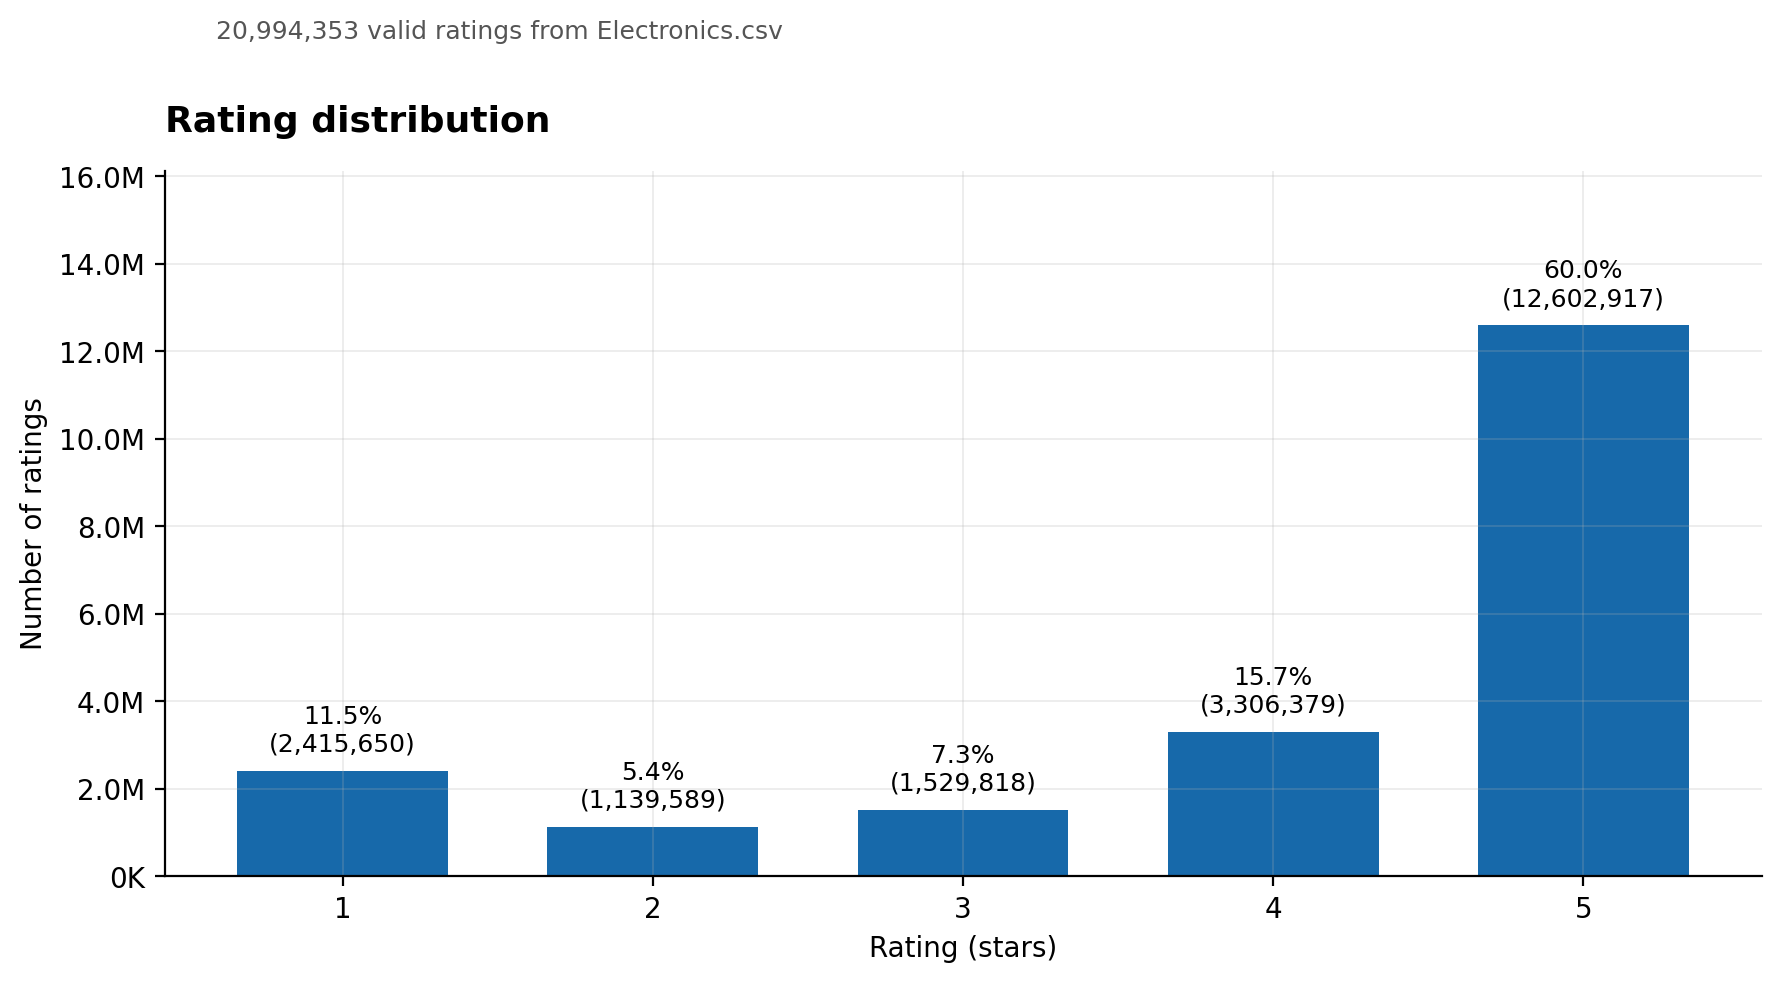

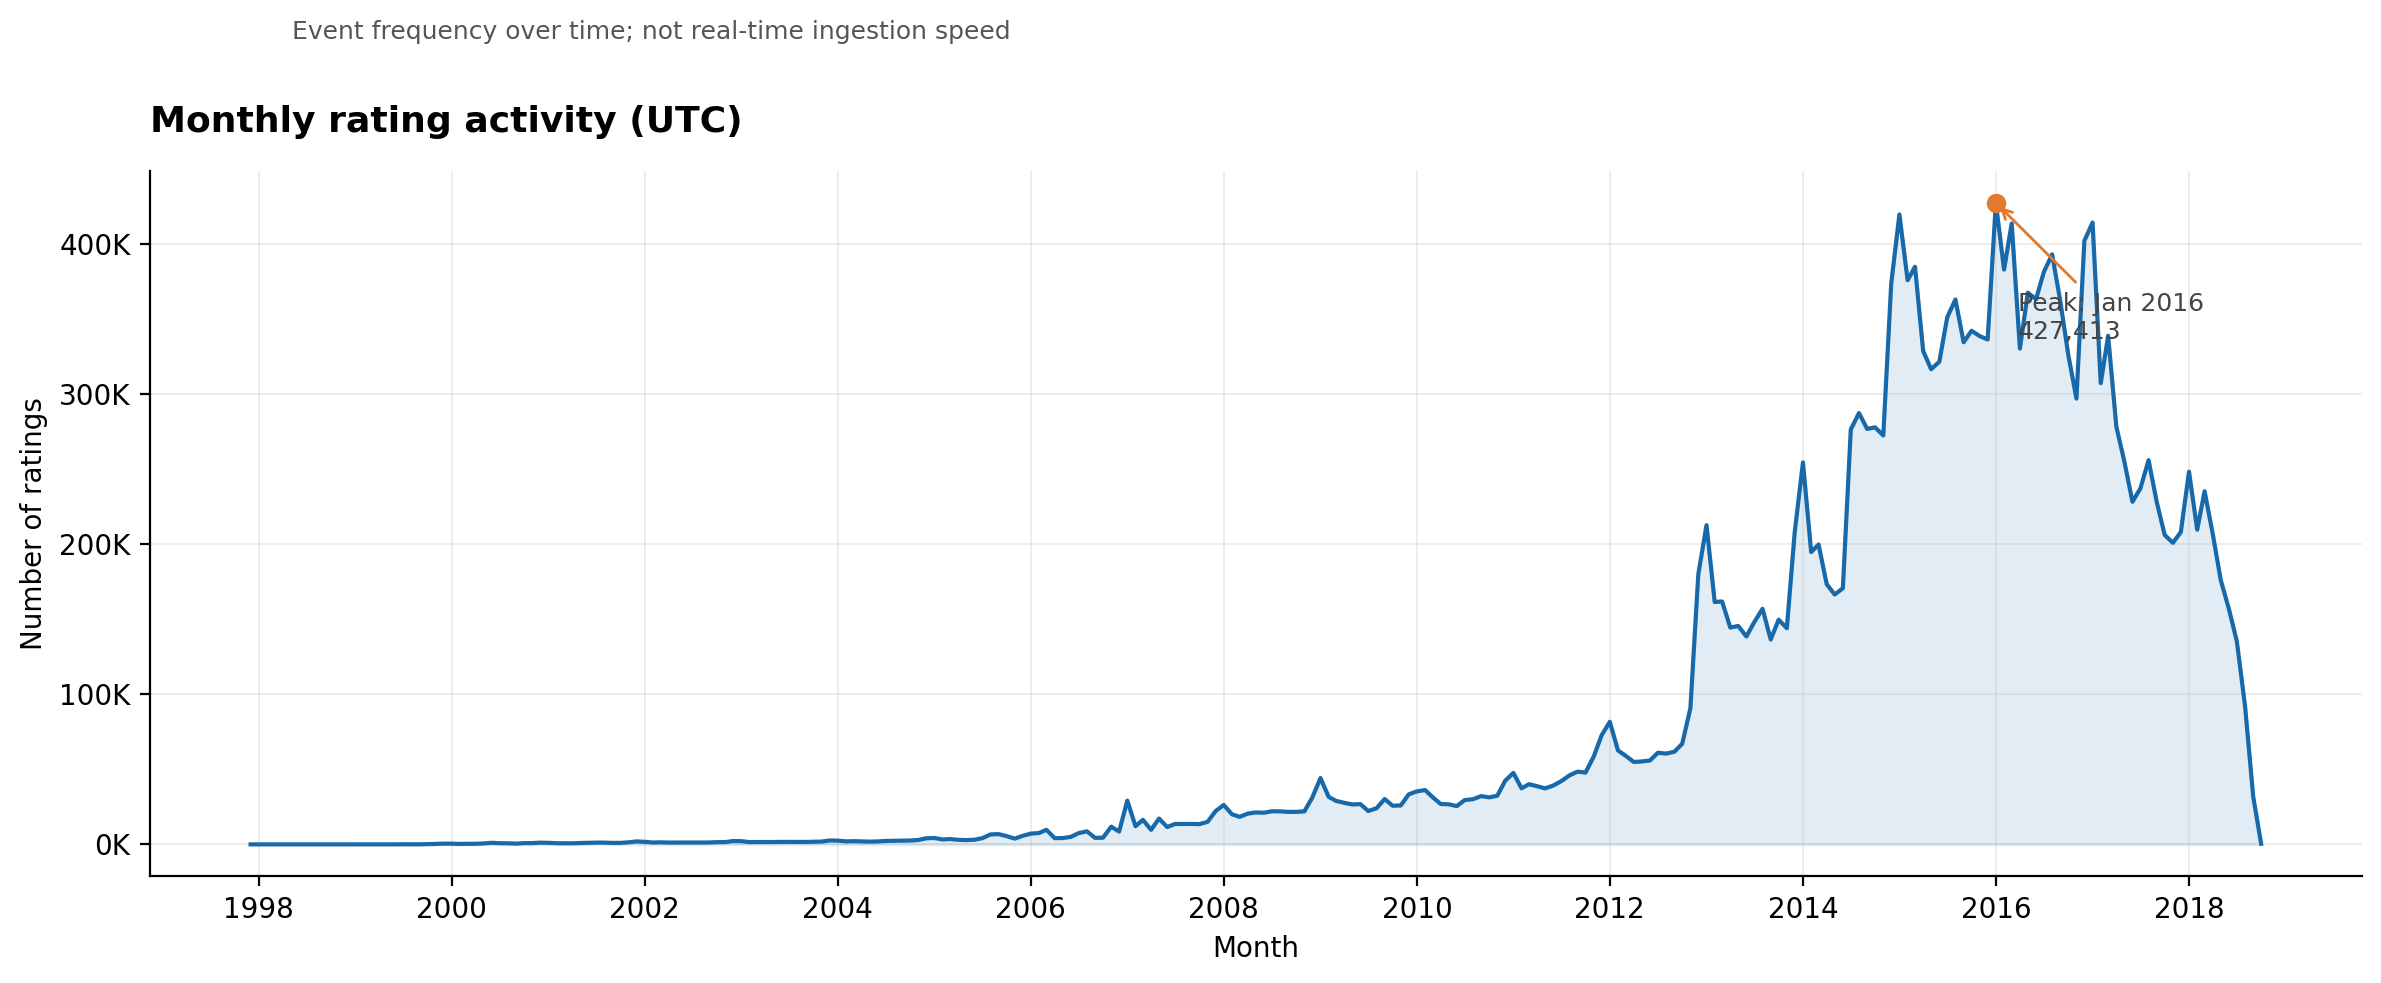

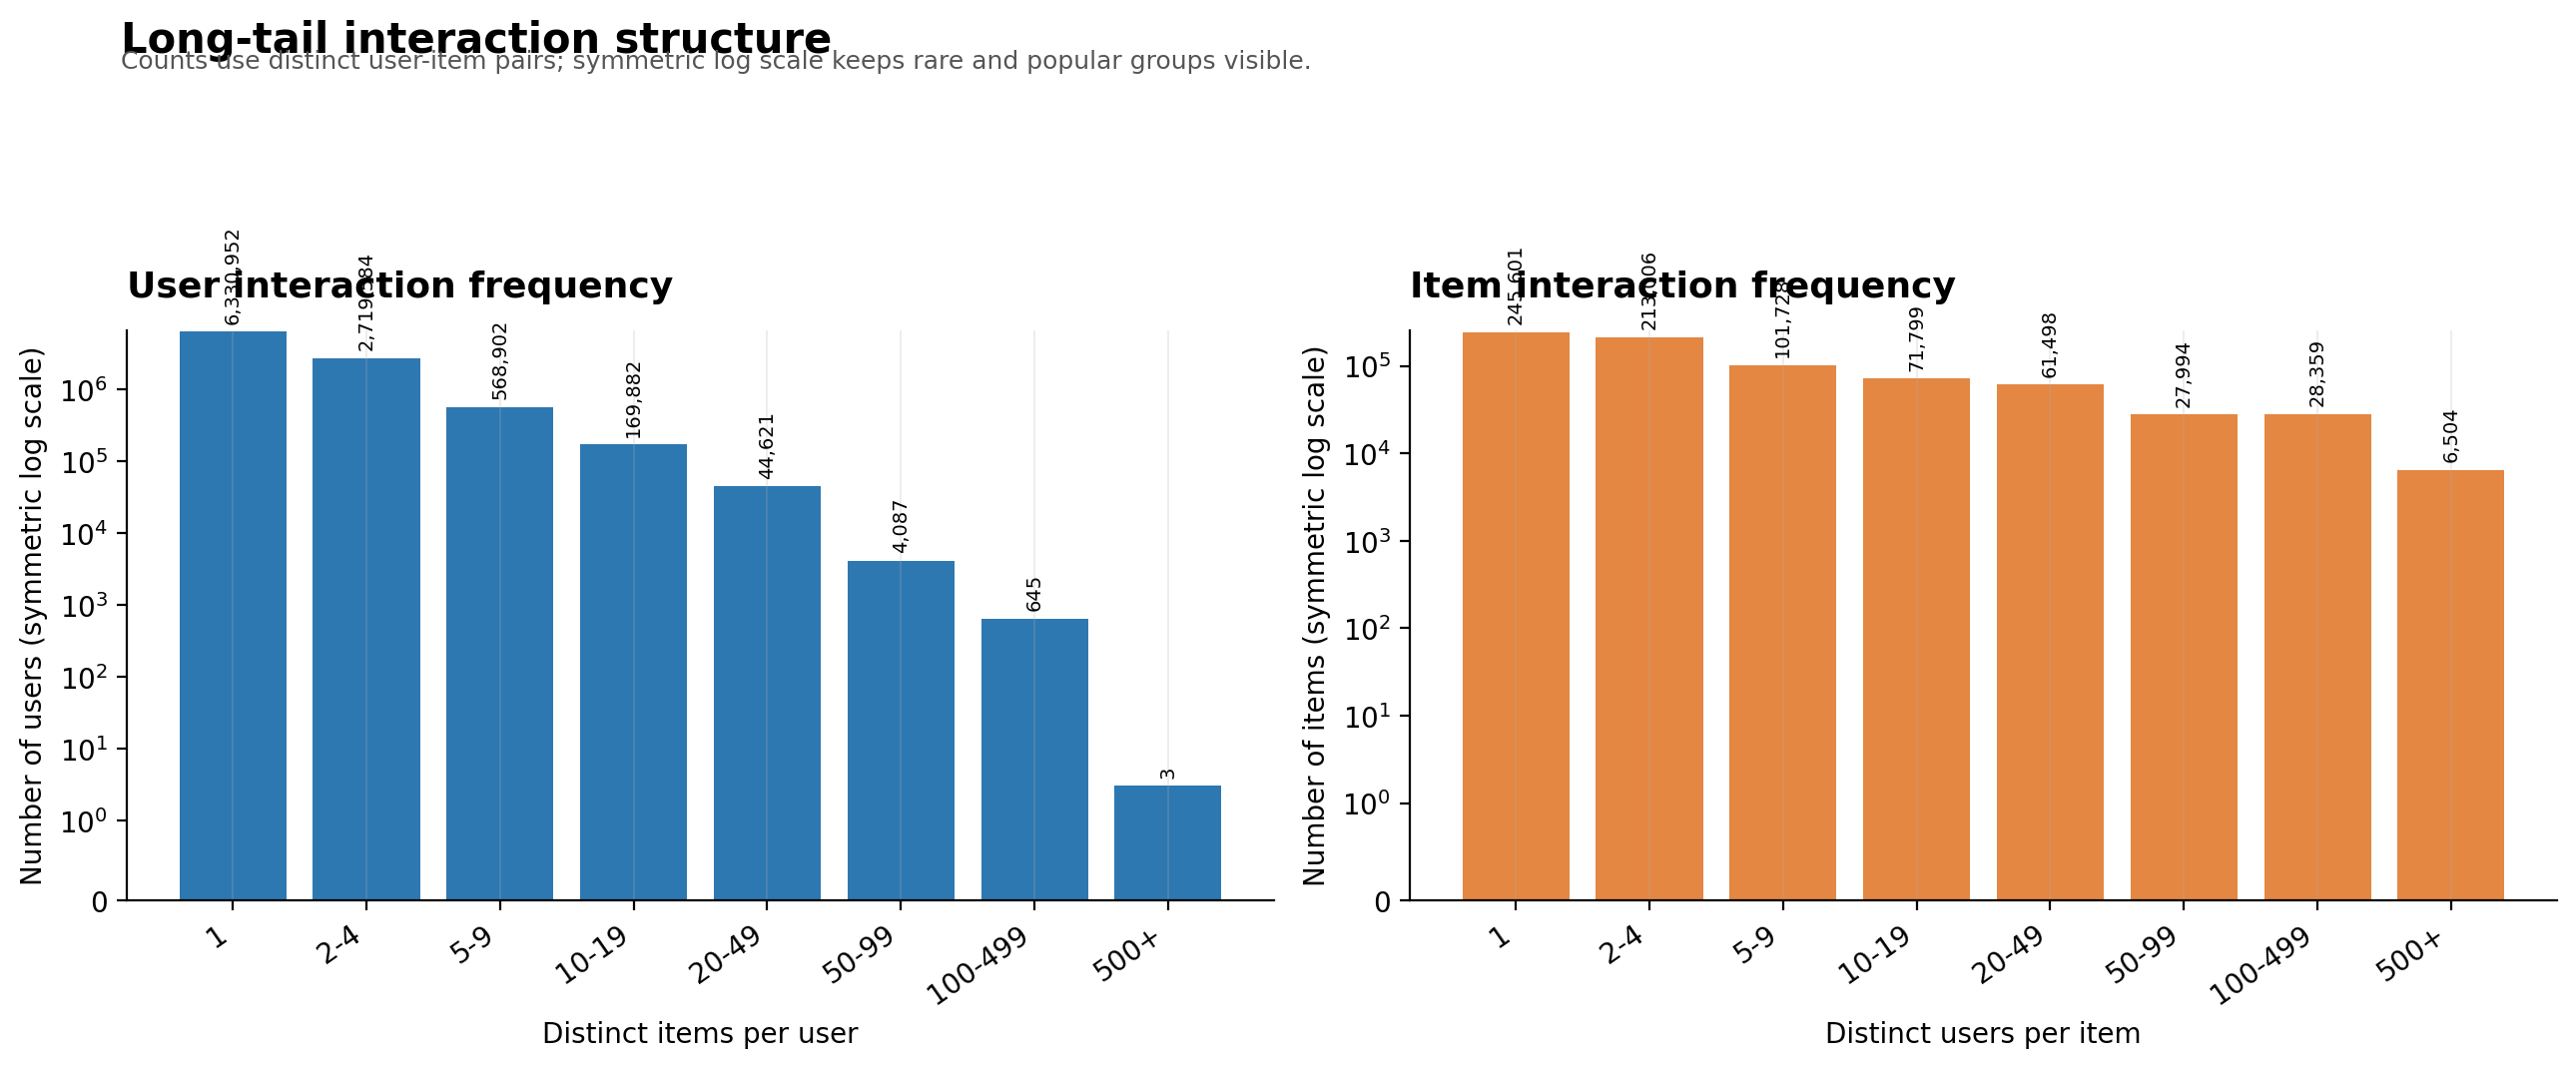

# EDA ? Amazon Electronics Ratings + Product Metadata

## Input files

- Ratings CSV: `D:\msis406\amazon-electronics-bigdata-recommender\data\raw\Electronics.csv`
- Metadata JSON: `D:\msis406\amazon-electronics-bigdata-recommender\data\raw\meta_Electronics.json\meta_Electronics.json`

Input: `D:\msis406\amazon-electronics-bigdata-recommender\data\raw\Electronics.csv`

- Total parsed rows: 20,994,353
- Valid rows: 20,994,353; invalid rows: 0
- Users: 9,838,676; items: 756,489
- Distinct user–item pairs: 20,553,480
- Sparsity: 99.99972385%
- Exact duplicate excess: 426,262
- Repeated-pair excess (includes exact duplicates): 440,873
- Historical period (UTC): 1997-12-04T00:00:00+00:00 → 2018-10-05T00:00:00+00:00

## Method notes

- Quality flags overlap; do not sum them.
- Blank lines are ignored by Spark CSV.
- No deduplication before rating/time distributions; use valid original rows.
- Sparsity and activity use distinct user-item pairs.
- Historical batch data; timestamps do not establish ingestion velocity.
- Remote/glob input requires input-version and an external file manifest.

## 5V evidence

- **Volume:** see counts above; local file bytes = 876247561. Compressed file size, if applicable, differs from decoded size.
- **Variety:** ratings come from `Electronics.csv`; product fields and join coverage come from `meta_Electronics.json`/`.gz`.
- **Velocity:** `monthly_activity.csv` and `figures/time_activity.png` show historical event frequency, not real-time ingestion speed.
- **Veracity:** `ratings_profile.json` gives missing/invalid counts and duplication. Error categories overlap. Excluded rows are not silently repaired.
- **Value:** supports testing Top-10 recommendations using Popularity and ALS; EDA does not prove recommendation quality.

## Interpretation

Sparsity = 1 − distinct(user,item) / (distinct users × distinct items). A large user–item matrix can be sparse even when the row count is large. Inspect the single-interaction entity counts and activity plots before designing evaluation.

Rating/time plots use all valid rows. Interaction histograms count distinct counterpart IDs, so duplicate ratings cannot inflate these histograms. No activity threshold is applied. No train/test split is created by this EDA; any later model preprocessing must fit its rules on training data only.

All sanity checks: True. Valid-row sample is sorted, deterministic, and not statistically representative. Inspect it against the source manually.


In [17]:
for filename in ['rating_distribution.png', 'time_activity.png', 'interaction_hist.png']:
    display(Image(filename=str(out / 'figures' / filename)))
display(Markdown((out / 'eda_summary.md').read_text(encoding='utf-8')))


## 13. Cách diễn giải và giới hạn

- **Độ thưa** = 1 − số cặp user–item duy nhất / (số user × số item). Không dùng số dòng thô khi có cặp lặp.
- Các cờ lỗi có thể chồng lấn, không cộng để ra tổng dòng lỗi. Dòng trắng được Spark bỏ qua; total là số bản ghi Spark đọc được.
- Exact duplicate được xác định sau trim ID/cast số; repeated-pair excess đã bao gồm exact duplicates, không cộng hai chỉ số.
- Rating/time distributions dùng mọi dòng hợp lệ, chưa loại trùng; histogram tương tác và độ thưa dùng cặp duy nhất.
- Sample hợp lệ được sắp xếp cố định để đối chiếu thủ công, không phải sample đại diện. Quantile hoạt động là xấp xỉ với sai số hạng tương đối 0,001; các phép distinct/count là chính xác.
- Không lọc user/item theo ngưỡng hoạt động ở EDA. Khi huấn luyện, xác định quy tắc lọc từ train để tránh leakage.
- Dữ liệu lịch sử không chứng minh realtime/ingest velocity. Chỉ có CSV 4 cột nên không thể phân tích nội dung review, category, brand hoặc sentiment.
- `code_sha256` trong JSON là `null` cho bản notebook; hãy lưu notebook cùng kết quả để truy vết code. SHA256 của CSV vẫn có đầy đủ.
- Thời lượng EDA tính từ bước 4, gồm thời gian chờ giữa các cell nếu chạy thủ công; **không dùng làm benchmark hiệu năng**. Muốn đo gần thời gian xử lý, restart kernel và Run All.

Nếu sửa đường dẫn hoặc logic, nên restart kernel rồi Run All để tránh dùng trạng thái cũ. Chỉ chạy cell dọn bộ nhớ dưới đây sau khi đã xem và lưu kết quả.


# Phần bổ sung — EDA mở rộng

**Các cell cũ và output gốc được giữ nguyên.** Phần này tái sử dụng `valid`, `pairs`, `activity`, `profile` và các thống kê đã có; không sửa dữ liệu, không lọc user/item và không thay đổi cách tính các chỉ số cũ. Cell `spark.stop()` được đưa xuống cuối để phần mới còn dùng được Spark.

**Cách chạy:** chạy từ đầu tới phần này, rồi chạy các cell bổ sung tuần tự. Nếu đã chạy cell kết thúc Spark, cần Restart Kernel và chạy lại. Các output mới hiện để trống vì chưa có CSV của bạn tại môi trường kiểm tra. Các output cũ là kết quả lần chạy bạn gửi.

Kết quả mới lưu riêng tại `OUTPUT_DIR/eda_extended/`; không ghi đè các JSON, CSV, PNG gốc. Không cần thêm Pandas hoặc Seaborn.

Phần chính chỉ thu các bảng tổng hợp nhỏ về Python. Phép join đo đồng thời ngưỡng user/item ở cuối là **tùy chọn, mặc định tắt** vì tốn shuffle. Các thống kê là mô tả toàn tập, không được dùng để lọc train dựa trên test.


## 14. Bảng chỉ số tổng quan và chất lượng có tỷ lệ

Phân biệt **số bản ghi**, **số cặp tương tác duy nhất**, **độ phủ ma trận** và **độ thưa**. Không có lỗi schema không đồng nghĩa không có review giả, thiên lệch chọn mẫu hoặc dữ liệu thiếu ngoài dataset.


In [18]:
import math
import html
from IPython.display import HTML
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter

required = ['valid', 'pairs', 'activity', 'profile', 'rating', 'quality']
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(f'Hãy chạy các cell gốc trước. Thiếu: {missing}')
try:
    if spark.sparkContext._jsc is None:
        raise RuntimeError('Spark đã dừng. Restart Kernel rồi chạy lại từ đầu.')
except AttributeError:
    raise RuntimeError('Spark không còn hoạt động. Restart Kernel rồi chạy lại từ đầu.')

extended_dir = out / 'eda_extended'
extended_figures = extended_dir / 'figures'
extended_figures.mkdir(parents=True, exist_ok=True)
extended_started = datetime.now(timezone.utc)
extended_begin = perf_counter()

def show_table(rows, columns=None):
    if not rows:
        display(Markdown('_Không có bản ghi._'))
        return
    columns = columns or list(rows[0])
    head = ''.join(f'<th style="text-align:left;padding:8px">{html.escape(str(c))}</th>' for c in columns)
    body = ''.join('<tr>' + ''.join(f'<td style="padding:7px;border-bottom:1px solid #ddd">{html.escape(str(row.get(c, "")))}</td>' for c in columns) + '</tr>' for row in rows)
    display(HTML(f'<div style="overflow-x:auto"><table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table></div>'))

def save_extended_figure(fig, filename):
    fig.tight_layout()
    path = extended_figures / filename
    fig.savefig(path, dpi=160, bbox_inches='tight')
    plt.close(fig)
    display(Image(filename=str(path)))

quality_table = [{'check': key, 'rows': int(value), 'percent_of_raw': 100 * value / total}
                 for key, value in quality.items()]
save_csv(extended_dir / 'quality_rates.csv', quality_table, ['check', 'rows', 'percent_of_raw'])
summary_table = [
    {'metric': 'Parsed rows', 'value': f'{total:,}'},
    {'metric': 'Valid rows', 'value': f'{n:,} ({n/total:.2%})'},
    {'metric': 'Users / Items', 'value': f"{entities['user']:,} / {entities['item']:,}"},
    {'metric': 'Unique user-item pairs', 'value': f'{unique_pairs:,}'},
    {'metric': 'Possible user-item pairs', 'value': f"{entities['user'] * entities['item']:,}"},
    {'metric': 'Density', 'value': f'{1-sparsity:.8%}'},
    {'metric': 'Sparsity', 'value': f'{sparsity:.8%}'},
    {'metric': 'Mean rating', 'value': f"{profile['rating_statistics']['mean']:.4f}"},
    {'metric': 'UTC period', 'value': f"{profile['min_time_utc']} → {profile['max_time_utc']}"},
]
show_table(summary_table)
show_table([{**r, 'percent_of_raw': f"{r['percent_of_raw']:.4f}%"} for r in quality_table])


metric,value
Parsed rows,"20,994,353"
Valid rows,"20,994,353 (100.00%)"
Users / Items,"9,838,676 / 756,489"
Unique user-item pairs,"20,553,480"
Possible user-item pairs,"7,442,850,168,564"
Density,0.00027615%
Sparsity,99.99972385%
Mean rating,4.0737
UTC period,1997-12-04T00:00:00+00:00 → 2018-10-05T00:00:00+00:00


check,rows,percent_of_raw
malformed_csv,0,0.0000%
user_missing,0,0.0000%
item_missing,0,0.0000%
rating_missing,0,0.0000%
timestamp_missing,0,0.0000%
rating_invalid,0,0.0000%
timestamp_invalid,0,0.0000%
invalid,0,0.0000%


## 15. Long tail, mức tập trung và ngưỡng hoạt động

Mỗi user/item được đo bằng **số đối tượng duy nhất** họ tương tác. Từ bảng tần suất gộp theo số tương tác, tính chính xác tỷ trọng các cặp thuộc top 1%, 5%, 10%, 20% đối tượng. Số đối tượng top được làm tròn lên; các đối tượng đồng hạng có cùng số tương tác nên không ảnh hưởng tổng trọng số.

Bảng ngưỡng là **kiểm tra độ nhạy**, không thực sự xóa dòng. Tỷ lệ cặp giữ lại theo user và theo item được đo độc lập, **không phải** tỷ lệ giữ lại khi áp cả hai điều kiện. Lọc một lượt cũng không tương đương k-core lặp đến hội tụ.


In [19]:
# Group by activity count, not collect all user IDs or item IDs.
support_frequency = {}
concentration_rows, threshold_rows, tail_summary = [], [], {}
concentration_curves = {}
for kind, frame in activity.items():
    freq = [r.asDict() for r in frame.groupBy(F.col('count').alias('interactions'))
            .agg(F.count('*').alias('entities')).orderBy('interactions').collect()]
    support_frequency[kind] = freq
    assert sum(r['entities'] for r in freq) == entities[kind]
    assert sum(r['entities'] * r['interactions'] for r in freq) == unique_pairs
    save_csv(extended_dir / f'{kind}_support_frequency.csv', freq, ['interactions', 'entities'])
    N = entities[kind]
    ordered = list(reversed(freq))
    cumulative_entities, cumulative_pairs = 0, 0
    curve_x, curve_y = [0.0], [0.0]
    for row in ordered:
        cumulative_entities += row['entities']
        cumulative_pairs += row['entities'] * row['interactions']
        curve_x.append(cumulative_entities / N)
        curve_y.append(cumulative_pairs / unique_pairs)
    concentration_curves[kind] = (curve_x, curve_y)
    # Integral of ascending Lorenz curve; each tied-count segment is linear.
    x, y, area = 0.0, 0.0, 0.0
    for row in freq:
        nx = x + row['entities'] / N
        ny = y + row['entities'] * row['interactions'] / unique_pairs
        area += (nx - x) * (ny + y) / 2
        x, y = nx, ny
    gini = max(0.0, min(1.0, 1 - 2 * area))
    for fraction in [0.01, 0.05, 0.10, 0.20]:
        target = max(1, math.ceil(N * fraction))
        left, mass = target, 0
        for row in ordered:
            taken = min(left, row['entities'])
            mass += taken * row['interactions']
            left -= taken
            if not left:
                break
        concentration_rows.append({'kind': kind, 'target_top_fraction': fraction,
                                   'selected_entities': target, 'actual_entity_fraction': target / N,
                                   'pair_fraction': mass / unique_pairs})
    single = sum(r['entities'] for r in freq if r['interactions'] == 1)
    tail_summary[kind] = {'single_interaction_fraction': single / N, 'gini_activity': gini}
    for threshold in [1, 2, 3, 5, 10, 20, 50]:
        kept = [r for r in freq if r['interactions'] >= threshold]
        count = sum(r['entities'] for r in kept)
        mass = sum(r['entities'] * r['interactions'] for r in kept)
        threshold_rows.append({'kind': kind, 'min_interactions': threshold,
                               'retained_entities': count, 'entity_fraction': count / N,
                               'retained_pairs': mass, 'pair_fraction': mass / unique_pairs})
save_csv(extended_dir / 'concentration.csv', concentration_rows, list(concentration_rows[0]))
save_csv(extended_dir / 'support_thresholds.csv', threshold_rows, list(threshold_rows[0]))
show_table([{'kind': k, 'single_interaction_entities': f"{v['single_interaction_fraction']:.2%}",
             'gini_activity': f"{v['gini_activity']:.4f}"} for k,v in tail_summary.items()])
show_table([{**r, 'actual_entity_fraction': f"{r['actual_entity_fraction']:.2%}",
             'pair_fraction': f"{r['pair_fraction']:.2%}"} for r in concentration_rows])
show_table([{**r, 'entity_fraction': f"{r['entity_fraction']:.2%}",
             'pair_fraction': f"{r['pair_fraction']:.2%}"} for r in threshold_rows])


kind,single_interaction_entities,gini_activity
user,64.35%,0.4296
item,32.47%,0.8623


kind,target_top_fraction,selected_entities,actual_entity_fraction,pair_fraction
user,0.01,98387,1.00%,11.65%
user,0.05,491934,5.00%,28.21%
user,0.1,983868,10.00%,39.61%
user,0.2,1967736,20.00%,54.21%
item,0.01,7565,1.00%,43.08%
item,0.05,37825,5.00%,70.60%
item,0.1,75649,10.00%,81.46%
item,0.2,151298,20.00%,90.20%


kind,min_interactions,retained_entities,entity_fraction,retained_pairs,pair_fraction
user,1,9838676,100.00%,20553480,100.00%
user,2,3507724,35.65%,14222528,69.20%
user,3,1849027,18.79%,10905134,53.06%
user,5,788140,8.01%,7358908,35.80%
user,10,219238,2.23%,3780757,18.39%
user,20,49356,0.50%,1588946,7.73%
user,50,4735,0.05%,361204,1.76%
item,1,756489,100.00%,20553480,100.00%
item,2,510888,67.53%,20307879,98.81%
item,3,402903,53.26%,20091909,97.75%


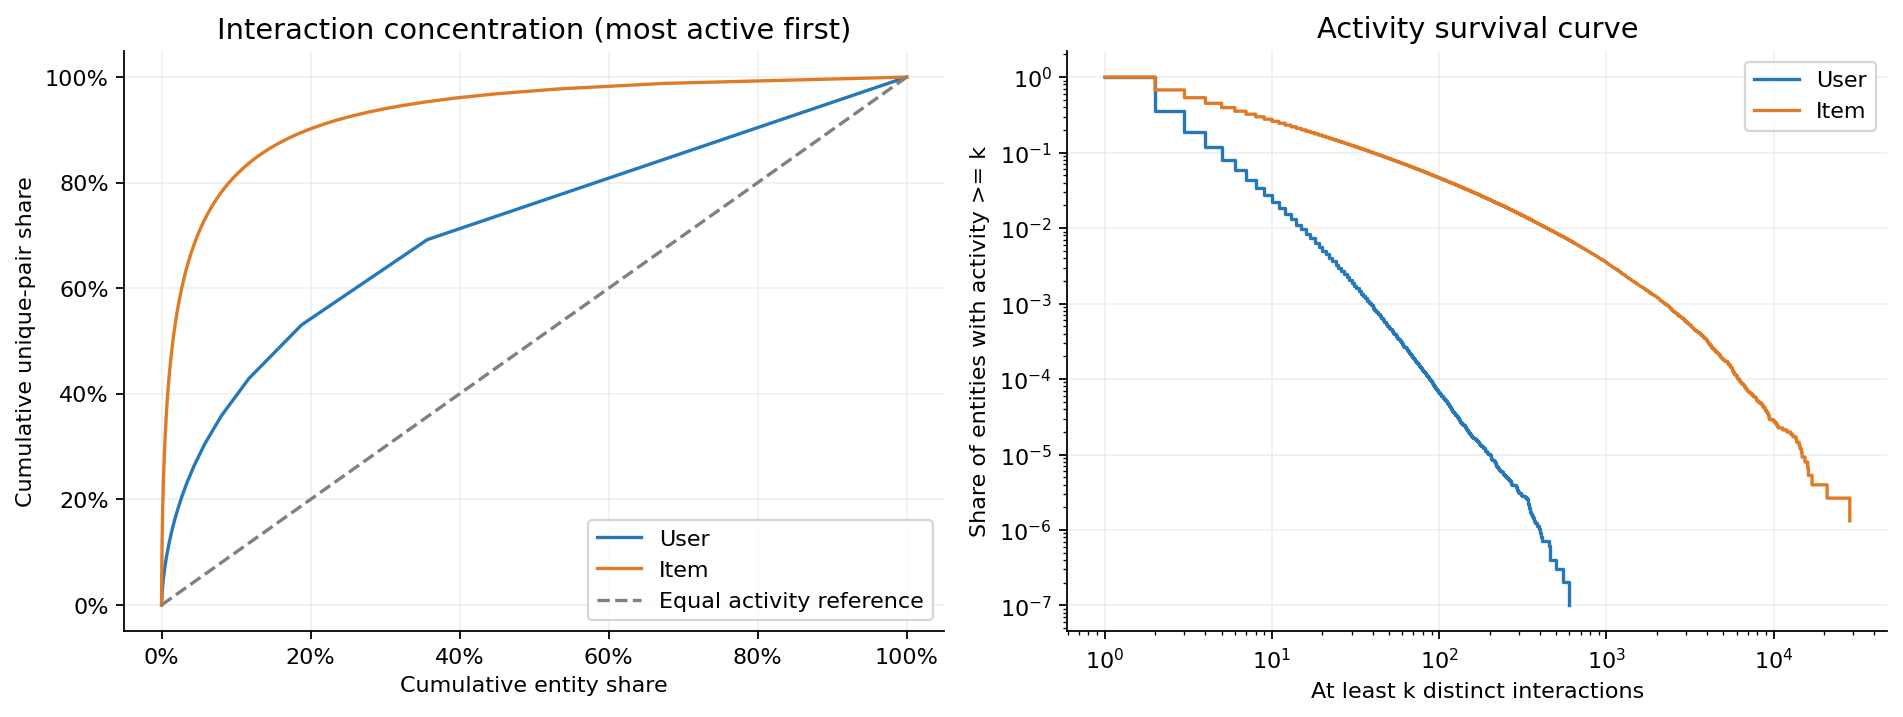

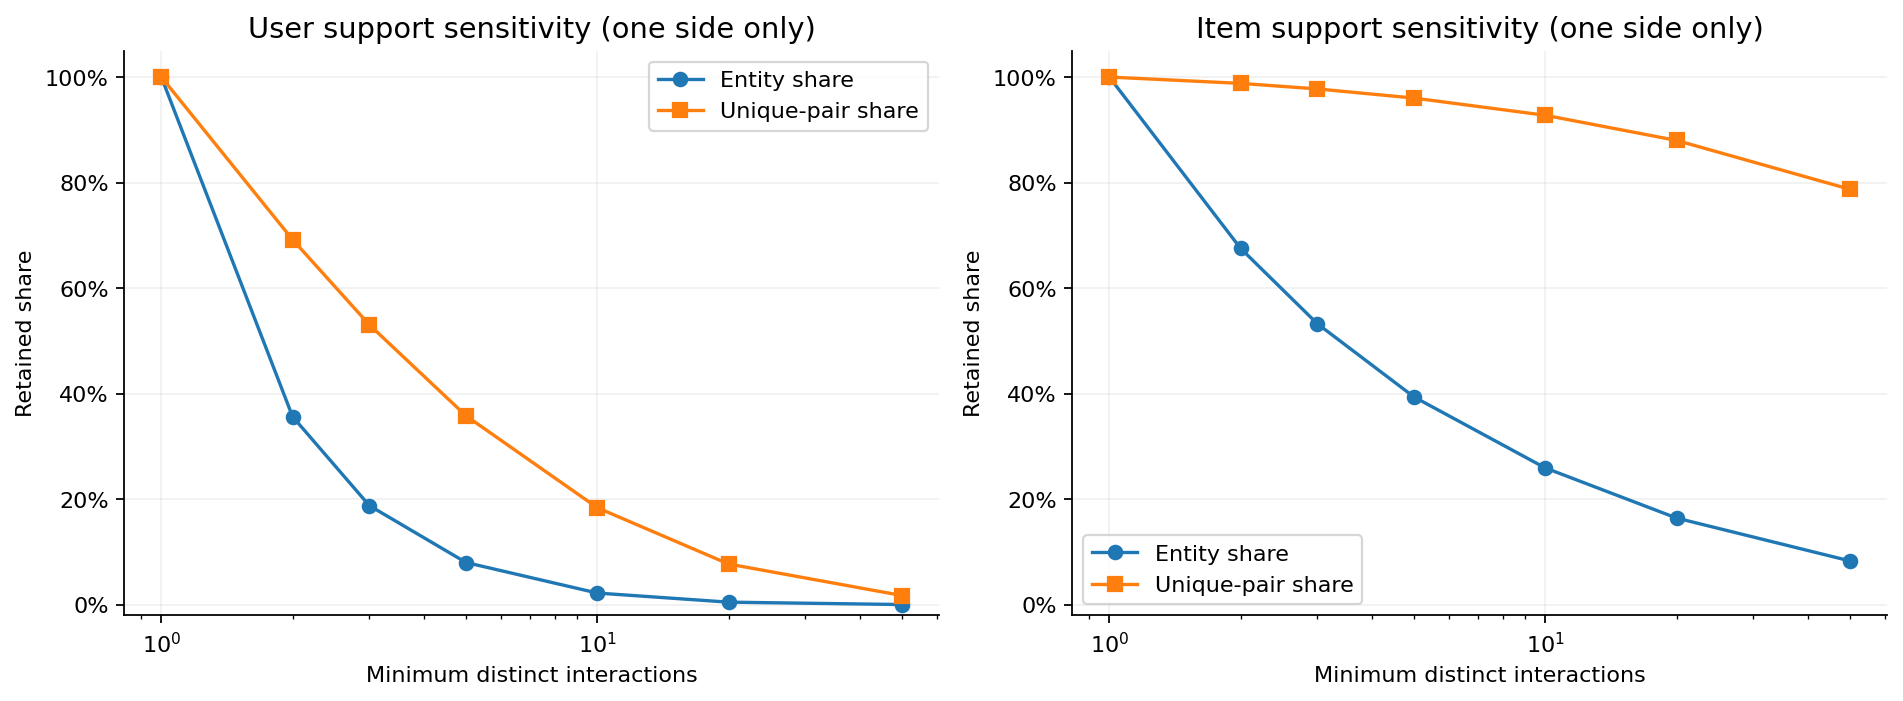

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
colors = {'user': '#2678b8', 'item': '#df7b27'}
for kind, (xs, ys) in concentration_curves.items():
    axes[0].plot(xs, ys, label=kind.title(), color=colors[kind])
    f = support_frequency[kind]
    remaining = entities[kind]
    xs_tail, ys_tail = [], []
    for row in f:
        xs_tail.append(row['interactions'])
        ys_tail.append(remaining / entities[kind])
        remaining -= row['entities']
    axes[1].step(xs_tail, ys_tail, where='post', label=kind.title(), color=colors[kind])
axes[0].plot([0,1], [0,1], '--', color='gray', label='Equal activity reference')
axes[0].set(title='Interaction concentration (most active first)', xlabel='Cumulative entity share', ylabel='Cumulative unique-pair share')
axes[1].set(title='Activity survival curve', xlabel='At least k distinct interactions', ylabel='Share of entities with activity >= k', xscale='log', yscale='log')
axes[0].xaxis.set_major_formatter(PercentFormatter(1)); axes[0].yaxis.set_major_formatter(PercentFormatter(1))
for ax in axes:
    ax.legend(); ax.grid(alpha=0.2)
save_extended_figure(fig, 'long_tail_concentration.png')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, kind in zip(axes, ['user', 'item']):
    rows = [r for r in threshold_rows if r['kind'] == kind]
    ax.plot([r['min_interactions'] for r in rows], [r['entity_fraction'] for r in rows], 'o-', label='Entity share')
    ax.plot([r['min_interactions'] for r in rows], [r['pair_fraction'] for r in rows], 's-', label='Unique-pair share')
    ax.set(title=f'{kind.title()} support sensitivity (one side only)', xlabel='Minimum distinct interactions', ylabel='Retained share', xscale='log', ylim=(-0.02,1.05))
    ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.grid(alpha=0.2); ax.legend()
save_extended_figure(fig, 'support_threshold_sensitivity.png')


## 16. Xu hướng chất lượng rating theo thời gian

Ngoài đếm rating/tháng, bổ sung rating trung bình, tỷ lệ 4–5 sao và phân bố 1–5 sao theo năm. Khoảng tháng không có rating được thể hiện bằng gap (không tự gán rating bằng 0). Những tháng ít quan sát có trung bình kém ổn định; số mẫu được biểu diễn ở cùng hình. Năm đầu/cuối có thể chỉ bao phủ một phần năm, nên không suy diễn tăng trưởng cả năm từ tổng chưa chuẩn hóa.

Điểm rating là đánh giá, không phải sentiment từ văn bản. Biến động chỉ là mô tả, không chứng minh nguyên nhân hoặc chất lượng sản phẩm thay đổi.


year,ratings,observed_months,mean_rating,4-5_star_share
1997,1,1,5.000,100.00%
1998,2,2,5.000,100.00%
1999,"1,074",8,4.026,76.54%
2000,"7,981",12,4.086,78.44%
2001,"12,905",12,3.926,73.45%
2002,"16,818",12,3.836,70.50%
2003,"21,075",12,3.753,68.01%
2004,"29,009",12,3.559,62.36%
2005,"52,553",12,3.628,64.64%
2006,"83,028",12,3.745,67.90%


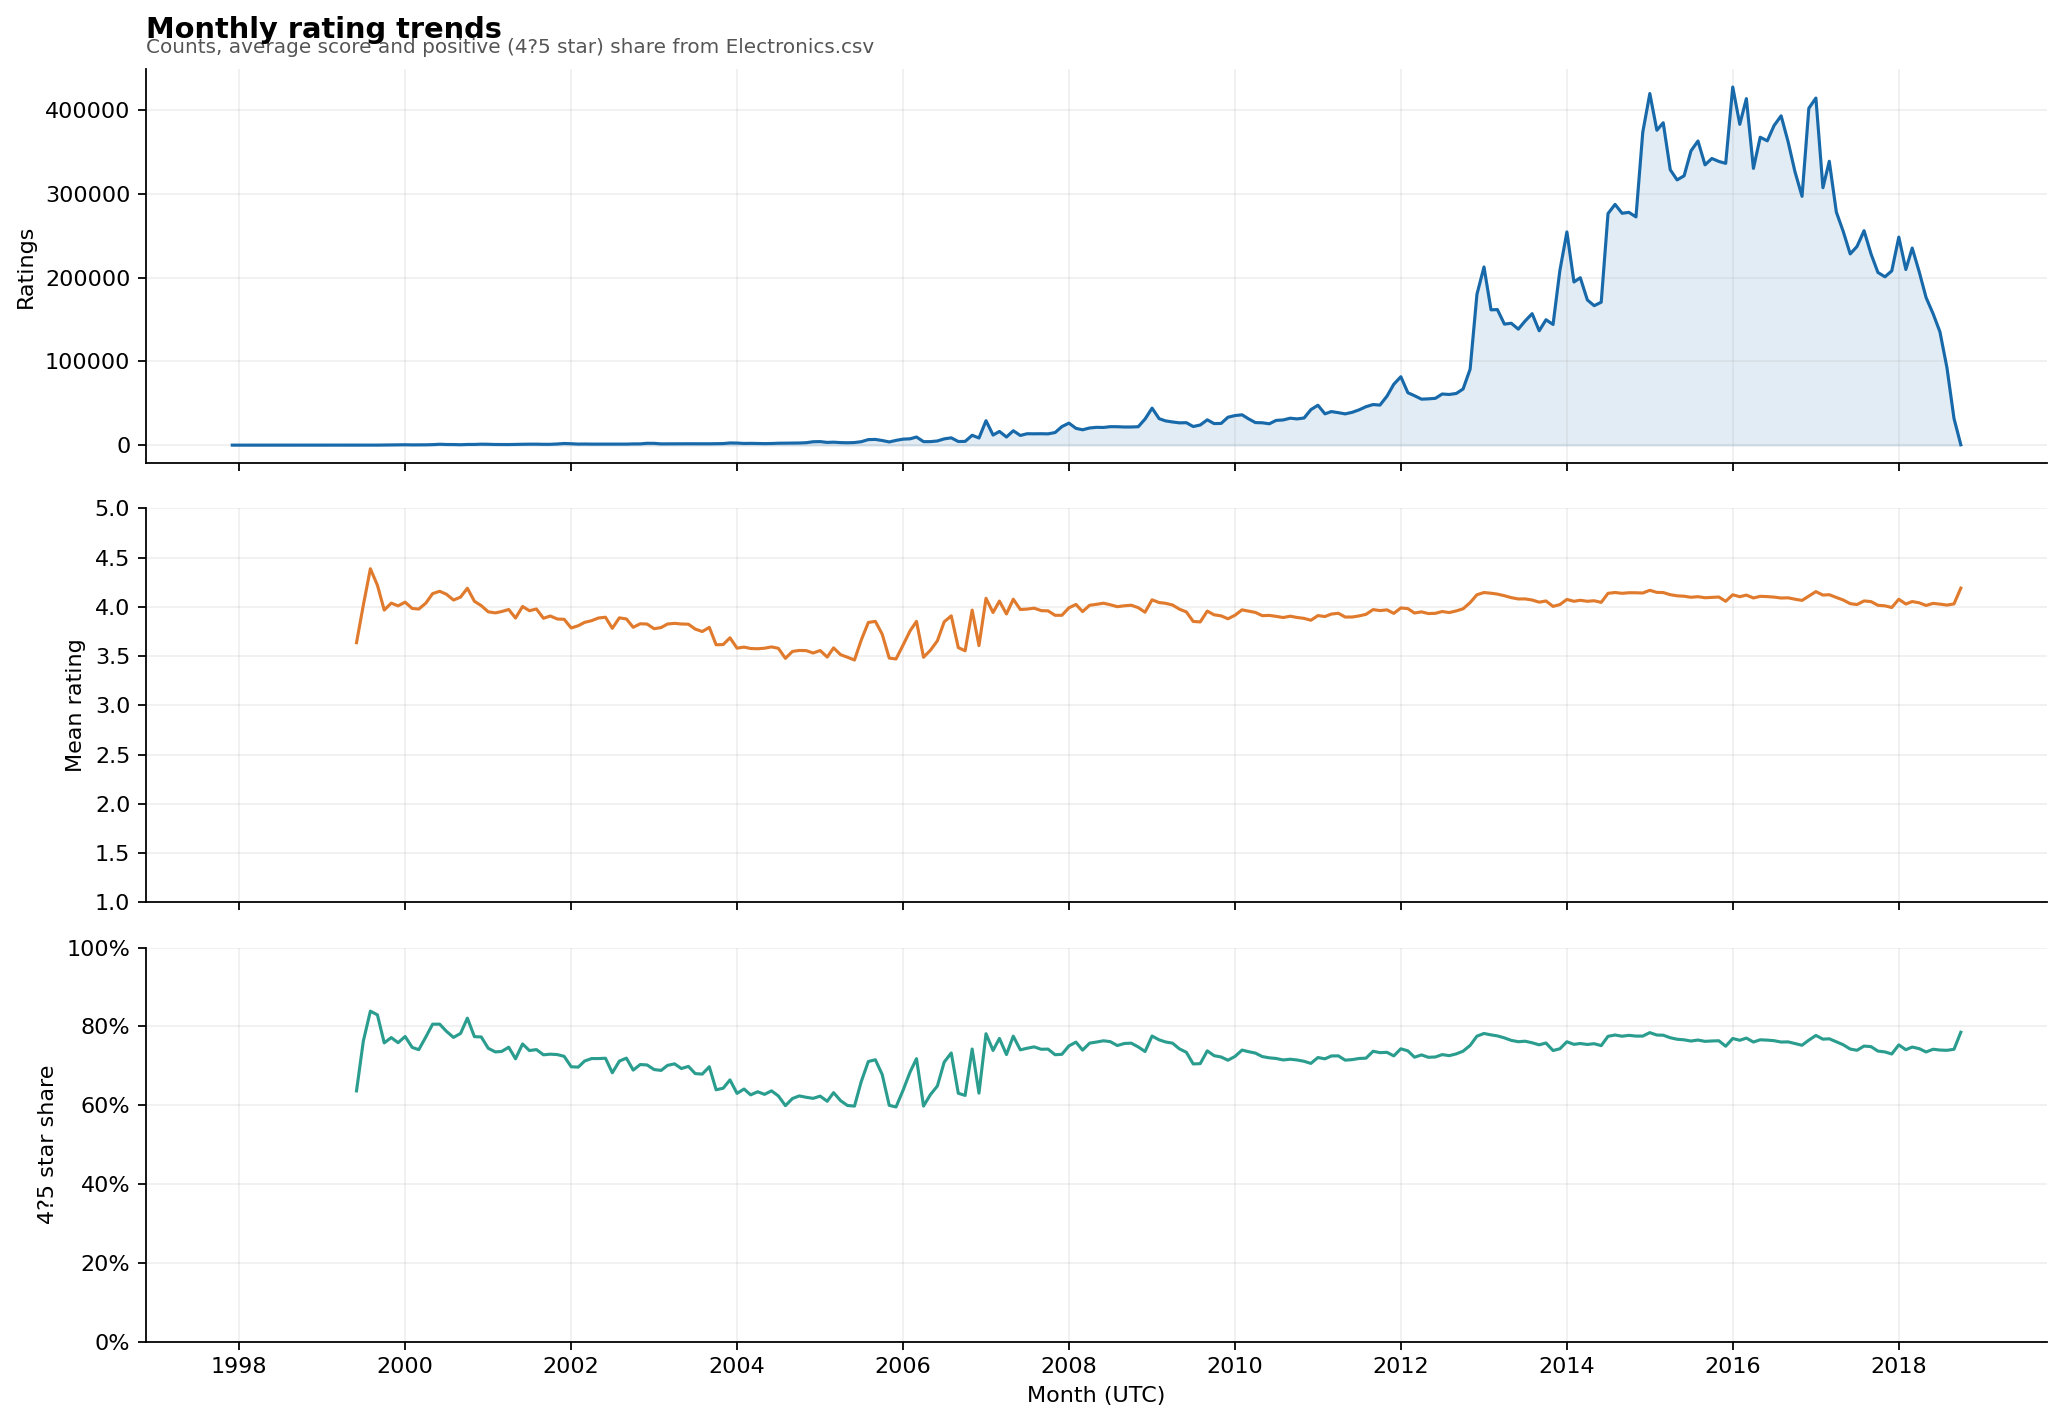

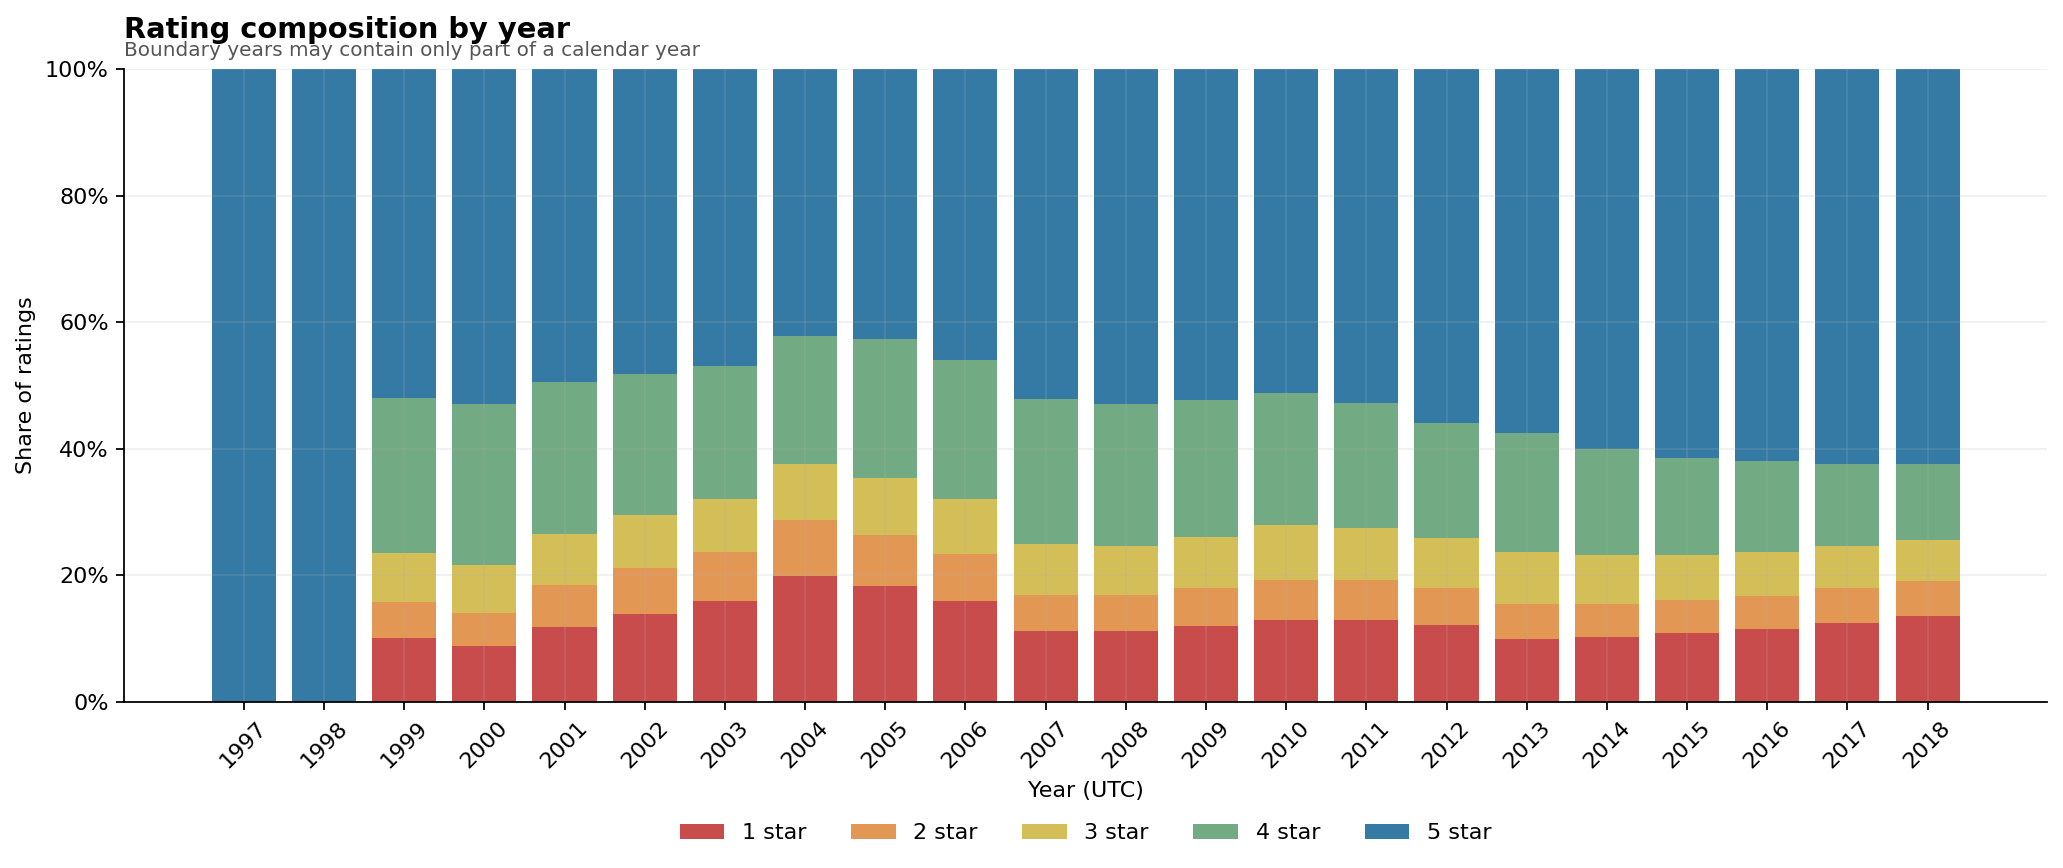

In [21]:
monthly_detail = [r.asDict() for r in dated.groupBy(F.date_format('review_date', 'yyyy-MM').alias('month')).agg(
    F.count('*').alias('ratings'), F.avg('rating').alias('mean_rating'),
    F.sum((F.col('rating') >= 4).cast('long')).alias('positive_ratings'),
    *[F.sum((F.col('rating') == k).cast('long')).alias(f'stars_{k}') for k in range(1,6)]
).orderBy('month').collect()]
for row in monthly_detail:
    row['positive_fraction'] = row['positive_ratings'] / row['ratings']
assert sum(r['ratings'] for r in monthly_detail) == n
assert all(sum(r[f'stars_{k}'] for k in range(1,6)) == r['ratings'] for r in monthly_detail)
save_csv(extended_dir / 'monthly_rating_detail.csv', monthly_detail, list(monthly_detail[0]))
annual = {}
for row in monthly_detail:
    year = int(row['month'][:4])
    a = annual.setdefault(year, {'year': year, 'ratings': 0, 'observed_months': 0, **{f'stars_{k}':0 for k in range(1,6)}})
    a['ratings'] += row['ratings']; a['observed_months'] += 1
    for k in range(1,6):
        a[f'stars_{k}'] += row[f'stars_{k}']
annual_detail = sorted(annual.values(), key=lambda r:r['year'])
for row in annual_detail:
    row['mean_rating'] = sum(k * row[f'stars_{k}'] for k in range(1,6)) / row['ratings']
    row['positive_fraction'] = (row['stars_4'] + row['stars_5']) / row['ratings']
save_csv(extended_dir / 'yearly_rating_detail.csv', annual_detail, list(annual_detail[0]))
show_table([{'year':r['year'], 'ratings':f"{r['ratings']:,}", 'observed_months':r['observed_months'],
             'mean_rating':f"{r['mean_rating']:.3f}", '4-5_star_share':f"{r['positive_fraction']:.2%}"} for r in annual_detail])

lookup = {r['month']:r for r in monthly_detail}
y, m = map(int, min(lookup).split('-'))
dates, means, positive, volumes = [], [], [], []
while f'{y:04d}-{m:02d}' <= max(lookup):
    key = f'{y:04d}-{m:02d}'; row = lookup.get(key)
    dates.append(datetime(y,m,1))
    means.append(row['mean_rating'] if row else float('nan'))
    positive.append(row['positive_fraction'] if row else float('nan'))
    volumes.append(row['ratings'] if row else 0)
    y,m = (y+1,1) if m == 12 else (y,m+1)
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
axes[0].plot(dates, volumes, color='#1769aa', linewidth=1.4)
axes[0].fill_between(dates, volumes, color='#1769aa', alpha=0.12)
axes[0].set_ylabel('Ratings')
axes[0].set_title('Monthly rating trends', loc='left', fontweight='bold', pad=14)
axes[0].text(0, 1.04, 'Counts, average score and positive (4?5 star) share from Electronics.csv',
             transform=axes[0].transAxes, color='#555555', fontsize=9)
axes[1].plot(dates, means, color='#e07a2d', linewidth=1.4)
axes[1].set_ylabel('Mean rating')
axes[1].set_ylim(1, 5)
axes[2].plot(dates, positive, color='#2a9d8f', linewidth=1.4)
axes[2].set_ylabel('4?5 star share')
axes[2].set_xlabel('Month (UTC)')
axes[2].set_ylim(0, 1)
axes[2].yaxis.set_major_formatter(PercentFormatter(1))
for ax in axes:
    ax.grid(alpha=0.22)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
axes[2].xaxis.set_major_locator(mdates.YearLocator(2))
axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
fig.tight_layout(rect=[0, 0, 1, 0.95])
save_extended_figure(fig, 'monthly_rating_trends.png')

fig, ax = plt.subplots(figsize=(13, 5.4))
bottom = [0.0] * len(annual_detail)
star_colors = ['#c94c4c', '#e39754', '#d4be57', '#72ab83', '#347aa4']
for k, color in zip(range(1, 6), star_colors):
    values = [r[f'stars_{k}'] / r['ratings'] for r in annual_detail]
    ax.bar([str(r['year']) for r in annual_detail], values, bottom=bottom, label=f'{k} star', color=color)
    bottom = [a + b for a, b in zip(bottom, values)]
ax.set_title('Rating composition by year', loc='left', fontweight='bold', pad=14)
ax.text(0, 1.02, 'Boundary years may contain only part of a calendar year', transform=ax.transAxes,
        color='#555555', fontsize=9)
ax.set_xlabel('Year (UTC)')
ax.set_ylabel('Share of ratings')
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.tick_params(axis='x', rotation=45)
ax.legend(ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.16), frameon=False)
fig.tight_layout(rect=[0, 0.12, 1, 1])
save_extended_figure(fig, 'yearly_rating_composition.png')



## 17. Dashboard cho báo cáo

Các biểu đồ dưới đây dùng thống kê đã tổng hợp, không quét lại CSV. Tỷ trọng top 1% được tính theo cặp tương tác duy nhất; tỷ lệ rating 4–5 sao tính trên mọi dòng hợp lệ. Hai mẫu số này được giữ riêng.


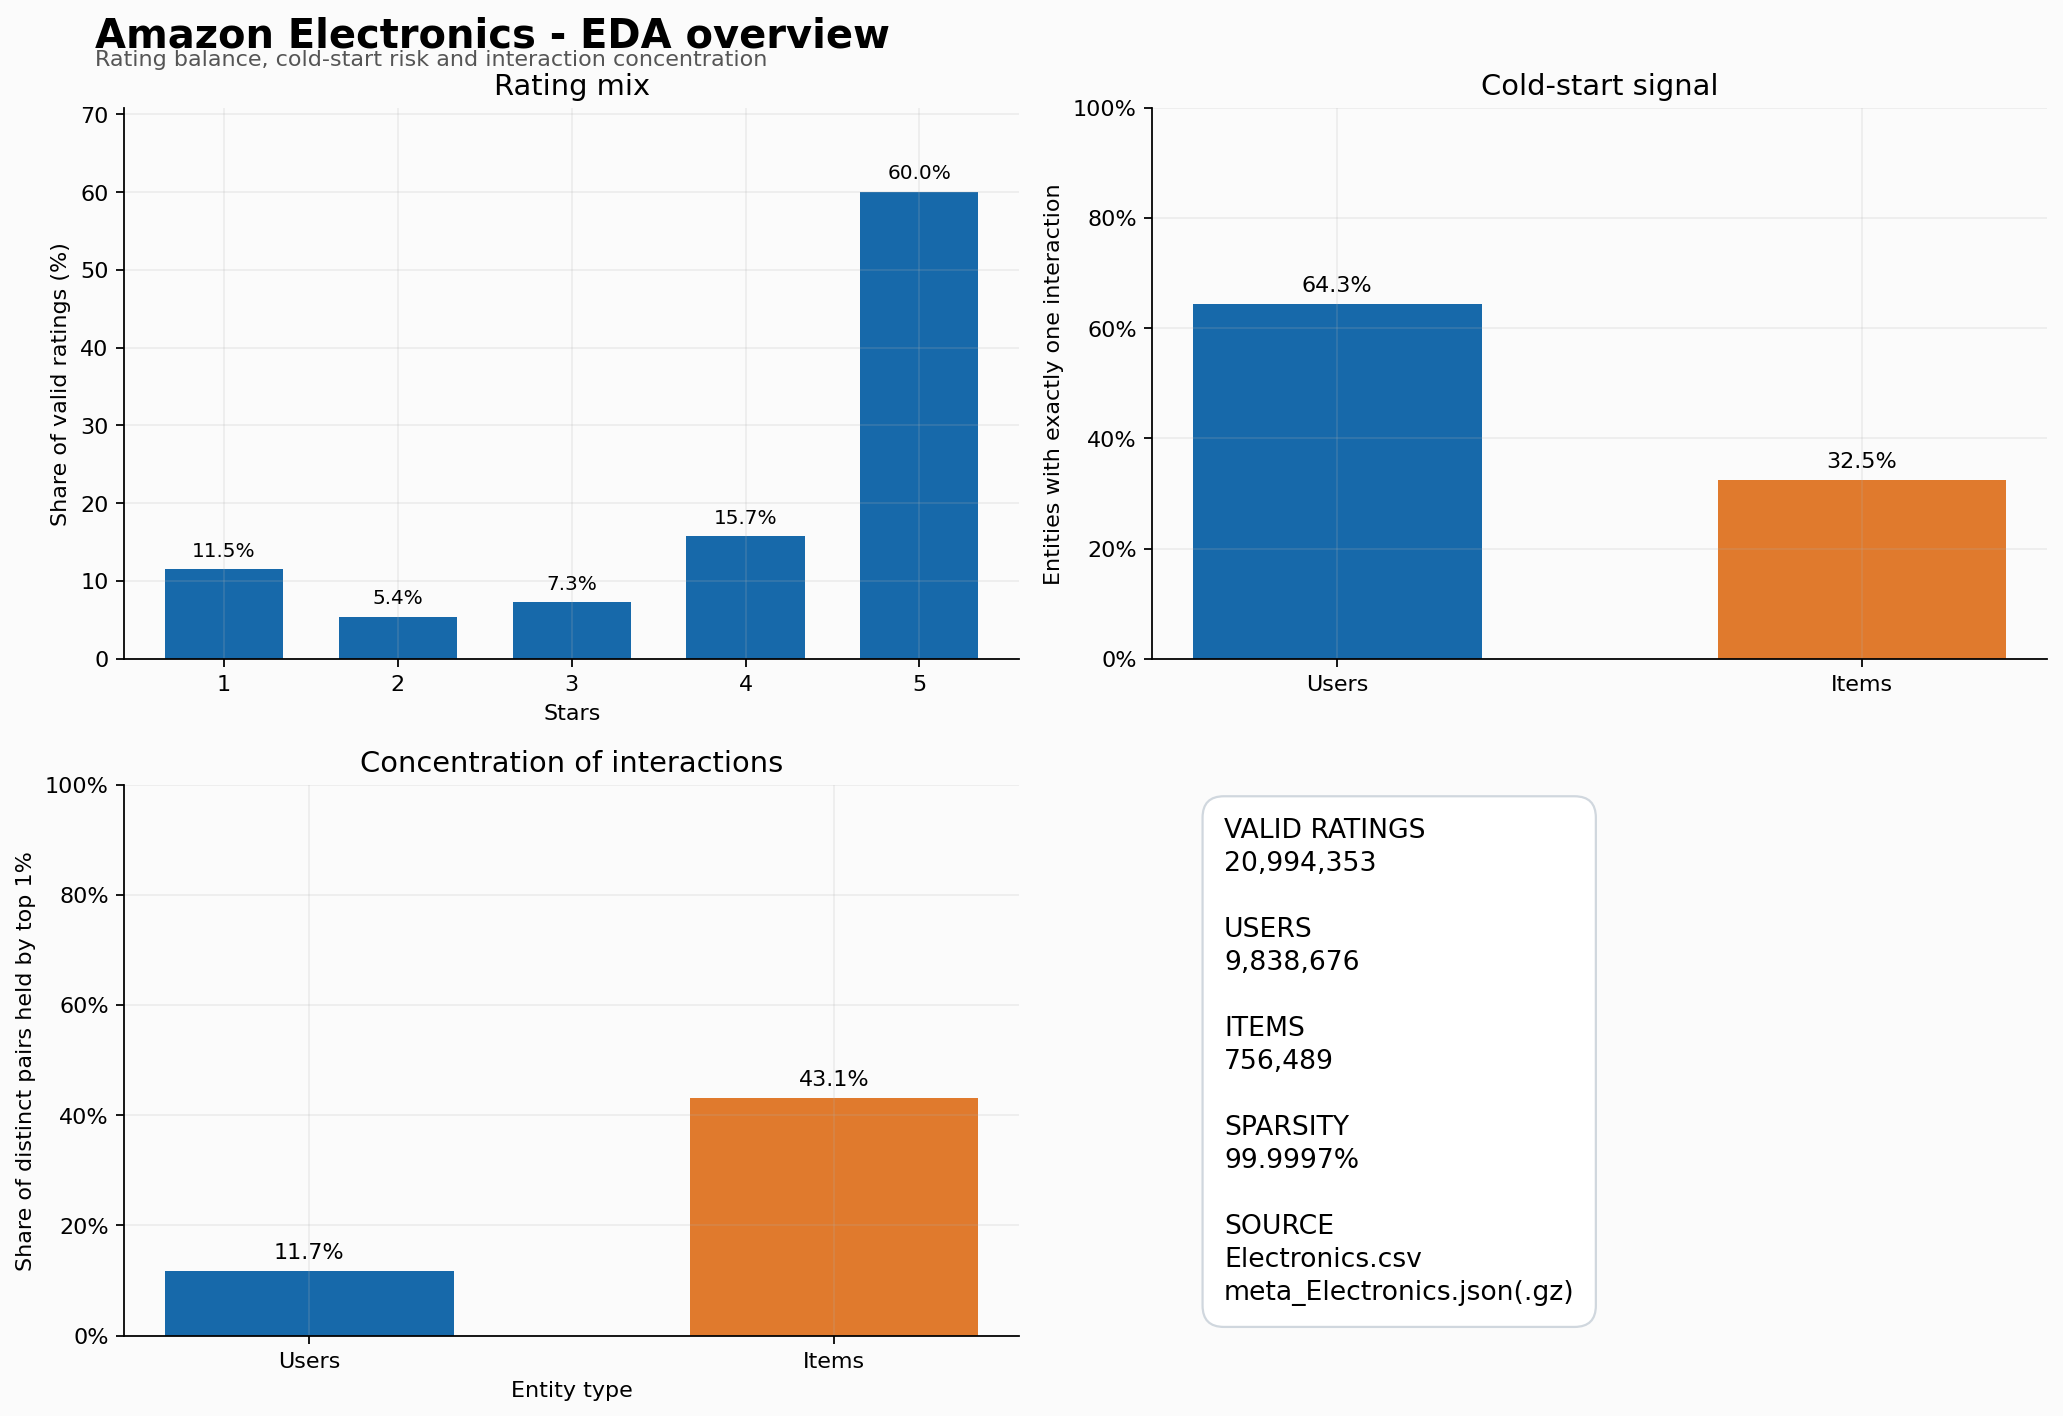

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.patch.set_facecolor('#fbfbfb')
for ax in axes.flat:
    ax.set_facecolor('#fbfbfb')

counts = [r['count'] for r in rating]
bars = axes[0, 0].bar(range(1, 6), [100 * c / n for c in counts], color='#1769aa', width=0.68)
for bar, count in zip(bars, counts):
    axes[0, 0].annotate(f'{count / n:.1%}', (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                        ha='center', va='bottom', fontsize=9, xytext=(0, 4), textcoords='offset points')
axes[0, 0].set(title='Rating mix', xlabel='Stars', ylabel='Share of valid ratings (%)', xticks=range(1, 6))
axes[0, 0].set_ylim(0, max(100 * c / n for c in counts) * 1.18)

labels = ['Users', 'Items']
values = [tail_summary[k]['single_interaction_fraction'] for k in ['user', 'item']]
bars = axes[0, 1].bar(labels, values, color=['#1769aa', '#e07a2d'], width=0.55)
for bar, value in zip(bars, values):
    axes[0, 1].annotate(f'{value:.1%}', (bar.get_x() + bar.get_width() / 2, value),
                        ha='center', va='bottom', fontsize=10, xytext=(0, 4), textcoords='offset points')
axes[0, 1].set(title='Cold-start signal', ylabel='Entities with exactly one interaction', ylim=(0, 1))
axes[0, 1].yaxis.set_major_formatter(PercentFormatter(1))

values = [next(r['pair_fraction'] for r in concentration_rows if r['kind'] == k and r['target_top_fraction'] == 0.01)
          for k in ['user', 'item']]
bars = axes[1, 0].bar(labels, values, color=['#1769aa', '#e07a2d'], width=0.55)
for bar, value in zip(bars, values):
    axes[1, 0].annotate(f'{value:.1%}', (bar.get_x() + bar.get_width() / 2, value),
                        ha='center', va='bottom', fontsize=10, xytext=(0, 4), textcoords='offset points')
axes[1, 0].set(title='Concentration of interactions', xlabel='Entity type', ylabel='Share of distinct pairs held by top 1%', ylim=(0, 1))
axes[1, 0].yaxis.set_major_formatter(PercentFormatter(1))

axes[1, 1].axis('off')
text = (f'VALID RATINGS\n{n:,}\n\nUSERS\n{entities["user"]:,}\n\nITEMS\n{entities["item"]:,}\n\n'
        f'SPARSITY\n{sparsity:.4%}\n\nSOURCE\nElectronics.csv\nmeta_Electronics.json(.gz)')
axes[1, 1].text(0.08, 0.94, text, va='top', fontsize=12, linespacing=1.35,
                bbox={'boxstyle': 'round,pad=0.8', 'facecolor': 'white', 'edgecolor': '#d0d7de'})
fig.suptitle('Amazon Electronics - EDA overview', fontsize=18, fontweight='bold', x=0.05, ha='left', y=0.98)
fig.text(0.05, 0.945, 'Rating balance, cold-start risk and interaction concentration', fontsize=10, color='#555555')
fig.tight_layout(rect=[0, 0, 1, 0.90])
save_extended_figure(fig, 'eda_dashboard.png')


## 18. Tùy chọn: kiểm tra áp đồng thời ngưỡng user và item

Mặc định `RUN_JOINT_SUPPORT = False`. Chỉ bật khi cần vì phép join trên toàn bộ các cặp có thể tốn tài nguyên. Đây là **lọc một lượt dựa trên số tương tác của tập tham chiếu**, không phải 5-core. Không ghi subset hoặc tác động đến `valid`. Phép đo này không dùng để chọn người dùng dựa vào tập test.


In [23]:
RUN_JOINT_SUPPORT = False
joint_support_rows = []
if RUN_JOINT_SUPPORT:
    joined = (pairs.join(activity['user'].withColumnRenamed('count','user_support'), 'user_id')
              .join(activity['item'].withColumnRenamed('count','item_support'), 'item_id'))
    values = joined.agg(*[
        F.sum(((F.col('user_support') >= k) & (F.col('item_support') >= k)).cast('long')).alias(f'k_{k}')
        for k in [1,2,5,10]
    ]).first().asDict()
    joint_support_rows = [{'min_user_support':k, 'min_item_support':k,
                           'retained_pairs_one_pass':values[f'k_{k}'],
                           'pair_fraction':values[f'k_{k}']/unique_pairs} for k in [1,2,5,10]]
    assert joint_support_rows[0]['retained_pairs_one_pass'] == unique_pairs
    save_csv(extended_dir / 'joint_support_one_pass.csv', joint_support_rows, list(joint_support_rows[0]))
    show_table(joint_support_rows)
else:
    print('Bỏ qua phép join tùy chọn; các phân tích chính đã đủ để chạy phần tổng kết.')


Bỏ qua phép join tùy chọn; các phân tích chính đã đủ để chạy phần tổng kết.


## 19. Nhận xét tự động, giới hạn và báo cáo 5V

Sinh nhận xét từ chính lần chạy hiện tại, không dùng số liệu cố định. JSON mở rộng liên kết với SHA256 của CSV gốc. Báo cáo phân biệt điều kiện hợp lệ schema và độ tin cậy nội dung; nêu rõ Variety/Velocity còn hạn chế.


In [24]:
positive_fraction = sum(r['count'] for r in rating if r['rating'] >= 4) / n
item_top1 = next(r for r in concentration_rows if r['kind']=='item' and r['target_top_fraction']==0.01)
user_threshold5 = next(r for r in threshold_rows if r['kind']=='user' and r['min_interactions']==5)
peak_month = max(monthly_detail,key=lambda r:r['ratings'])
notes = [
    f"Tập có {n:,} rating hợp lệ, {entities['user']:,} user và {entities['item']:,} item; độ thưa {sparsity:.8%}.",
    f"{positive_fraction:.2%} rating nằm ở mức 4–5 sao. Cần xem phân bố rating khi chọn baseline và đánh giá; đây không phải phân tích sentiment.",
    f"{tail_summary['user']['single_interaction_fraction']:.2%} user chỉ có một item duy nhất; cần báo cáo độ phủ dự đoán và trường hợp cold-start khi chia theo thời gian.",
    f"Top 1% item (làm tròn lên {item_top1['selected_entities']:,} item) chiếm {item_top1['pair_fraction']:.2%} các cặp tương tác duy nhất; cần đối chiếu ALS với Popularity và báo cáo coverage.",
    f"Nếu chỉ xét user có ít nhất 5 item, còn {user_threshold5['entity_fraction']:.2%} user và {user_threshold5['pair_fraction']:.2%} cặp. Đây là số liệu mô tả, chưa áp dụng lọc.",
    f"Tháng có nhiều rating nhất trong dữ liệu quan sát là {peak_month['month']} ({peak_month['ratings']:,}); không suy ra nguyên nhân hoặc tăng trưởng ngoài phạm vi dataset.",
    f"Có {quality['invalid']:,} dòng vi phạm quy tắc hợp lệ và {n-exact_unique_rows:,} dòng trùng dư sau chuẩn hóa; số 0 không chứng minh không có spam/review giả.",
]
limitations = [
    'Metadata sản phẩm được phân tích riêng ở phần metadata deep EDA; dataset không có nội dung review để phân tích sentiment.',
    'Dữ liệu lịch sử; tần suất event không phải tốc độ ingest hoặc realtime.',
    'User/item ID là định danh trong dataset, không chứng minh đại diện toàn bộ khách hàng/sản phẩm Amazon.',
    'Năm/tháng biên có thể chưa đủ kỳ; không so trực tiếp tổng kỳ thiếu với kỳ đầy đủ để kết luận tăng trưởng.',
    'Đây là EDA toàn tập; quy tắc lọc, mapping và lựa chọn tham số mô hình phải được học từ train.',
    'Không dựng ma trận user-item dạng dense; dùng biểu diễn tương tác thưa cho recommender.',
    'Cell mới chưa chạy trên CSV đầy đủ tại môi trường biên tập; output mới sẽ sinh khi bạn chạy notebook.',
]
full_report = '# EDA mở rộng — Amazon Electronics\n\n' + '\n'.join('- '+s for s in notes)
full_report += '\n\n## Giới hạn\n\n' + '\n'.join('- '+s for s in limitations)
(out / 'eda_extended' / 'eda_insights.md').write_text(full_report,encoding='utf-8')
size_text = f"{profile['local_input_bytes']:,} bytes" if profile.get('local_input_bytes') is not None else 'chưa đo bytes'
five_v_rows = [
    {'V':'Volume', 'evidence':f"{total:,} dòng đọc được; {n:,} hợp lệ; {size_text}; {unique_pairs:,} cặp duy nhất.", 'limit':'Quy mô file không tự chứng minh cần cluster; cần benchmark riêng.'},
    {'V':'Variety', 'evidence':'CSV gồm ID chuỗi, rating số và Unix timestamp.', 'limit':'Một định dạng; không có JSON/metadata/text trong phạm vi hiện tại.'},
    {'V':'Velocity', 'evidence':f"Lịch sử {profile['min_time_utc']} → {profile['max_time_utc']}; xem monthly_rating_detail.csv.", 'limit':'Chỉ event frequency lịch sử, không có thông tin tốc độ ingest hoặc SLA realtime.'},
    {'V':'Veracity', 'evidence':f"{quality['invalid']:,} dòng invalid; {n-exact_unique_rows:,} trùng dư; kiểm tra quality_rates.csv.", 'limit':'Valid schema không đồng nghĩa nội dung đúng hoặc mẫu không thiên lệch.'},
    {'V':'Value', 'evidence':f"Bài toán Top-10; {tail_summary['user']['single_interaction_fraction']:.2%} user có một tương tác, top1% item chiếm {item_top1['pair_fraction']:.2%} cặp.", 'limit':'Cần đánh giá ALS/Popularity bằng ranking metrics, coverage và xử lý cold-start; chưa chứng minh cải thiện kinh doanh.'},
]
five_v_md = '# Phân tích 5V dựa trên bằng chứng\n\n| V | Bằng chứng | Giới hạn |\n|---|---|---|\n'
for r in five_v_rows:
    five_v_md += f"| {r['V']} | {r['evidence']} | {r['limit']} |\n"
five_v_md += f"\nInput version: `{args.input_version}`. CSV SHA256: `{profile.get('local_file_sha256')}`.\n"
(extended_dir / 'data_5v.md').write_text(five_v_md,encoding='utf-8')
extended_profile = {
    'extension_version':'1.0', 'input_version':args.input_version,
    'input_sha256':profile.get('local_file_sha256'), 'base_profile':'../ratings_profile.json',
    'generated_at_utc':datetime.now(timezone.utc).isoformat(),
    'quality_rates':quality_table, 'positive_rating_fraction':positive_fraction,
    'activity_tail':tail_summary, 'concentration':concentration_rows,
    'support_thresholds_one_side':threshold_rows, 'joint_support_one_pass':joint_support_rows,
    'monthly_rating_detail':monthly_detail, 'yearly_rating_detail':annual_detail,
    'insights':notes, 'limitations':limitations,
    'sanity_checks':{
        'monthly_total_matches_valid':sum(r['ratings'] for r in monthly_detail)==n,
        'yearly_total_matches_valid':sum(r['ratings'] for r in annual_detail)==n,
        'threshold_retention_monotone':all(
            all(a['retained_pairs'] >= b['retained_pairs'] for a,b in zip(
                [r for r in threshold_rows if r['kind']==k], [r for r in threshold_rows if r['kind']==k][1:])) for k in ['user','item']),
        'concentration_curves_end_at_one':all(abs(v[0][-1]-1)<1e-10 and abs(v[1][-1]-1)<1e-10 for v in concentration_curves.values()),
    },
    'elapsed_wall_seconds_including_cell_waits':round(perf_counter()-extended_begin,3),
}
assert all(extended_profile['sanity_checks'].values())
(extended_dir / 'ratings_profile_extended.json').write_text(json.dumps(extended_profile,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
display(Markdown(full_report))
display(Markdown(five_v_md))
print('Đã lưu phần mở rộng:', extended_dir.resolve())


# EDA mở rộng — Amazon Electronics

- Tập có 20,994,353 rating hợp lệ, 9,838,676 user và 756,489 item; độ thưa 99.99972385%.
- 75.78% rating nằm ở mức 4–5 sao. Cần xem phân bố rating khi chọn baseline và đánh giá; đây không phải phân tích sentiment.
- 64.35% user chỉ có một item duy nhất; cần báo cáo độ phủ dự đoán và trường hợp cold-start khi chia theo thời gian.
- Top 1% item (làm tròn lên 7,565 item) chiếm 43.08% các cặp tương tác duy nhất; cần đối chiếu ALS với Popularity và báo cáo coverage.
- Nếu chỉ xét user có ít nhất 5 item, còn 8.01% user và 35.80% cặp. Đây là số liệu mô tả, chưa áp dụng lọc.
- Tháng có nhiều rating nhất trong dữ liệu quan sát là 2016-01 (427,413); không suy ra nguyên nhân hoặc tăng trưởng ngoài phạm vi dataset.
- Có 0 dòng vi phạm quy tắc hợp lệ và 426,262 dòng trùng dư sau chuẩn hóa; số 0 không chứng minh không có spam/review giả.

## Giới hạn

- Metadata sản phẩm được phân tích riêng ở phần metadata deep EDA; dataset không có nội dung review để phân tích sentiment.
- Dữ liệu lịch sử; tần suất event không phải tốc độ ingest hoặc realtime.
- User/item ID là định danh trong dataset, không chứng minh đại diện toàn bộ khách hàng/sản phẩm Amazon.
- Năm/tháng biên có thể chưa đủ kỳ; không so trực tiếp tổng kỳ thiếu với kỳ đầy đủ để kết luận tăng trưởng.
- Đây là EDA toàn tập; quy tắc lọc, mapping và lựa chọn tham số mô hình phải được học từ train.
- Không dựng ma trận user-item dạng dense; dùng biểu diễn tương tác thưa cho recommender.
- Cell mới chưa chạy trên CSV đầy đủ tại môi trường biên tập; output mới sẽ sinh khi bạn chạy notebook.

# Phân tích 5V dựa trên bằng chứng

| V | Bằng chứng | Giới hạn |
|---|---|---|
| Volume | 20,994,353 dòng đọc được; 20,994,353 hợp lệ; 876,247,561 bytes; 20,553,480 cặp duy nhất. | Quy mô file không tự chứng minh cần cluster; cần benchmark riêng. |
| Variety | CSV gồm ID chuỗi, rating số và Unix timestamp. | Một định dạng; không có JSON/metadata/text trong phạm vi hiện tại. |
| Velocity | Lịch sử 1997-12-04T00:00:00+00:00 → 2018-10-05T00:00:00+00:00; xem monthly_rating_detail.csv. | Chỉ event frequency lịch sử, không có thông tin tốc độ ingest hoặc SLA realtime. |
| Veracity | 0 dòng invalid; 426,262 trùng dư; kiểm tra quality_rates.csv. | Valid schema không đồng nghĩa nội dung đúng hoặc mẫu không thiên lệch. |
| Value | Bài toán Top-10; 64.35% user có một tương tác, top1% item chiếm 43.08% cặp. | Cần đánh giá ALS/Popularity bằng ranking metrics, coverage và xử lý cold-start; chưa chứng minh cải thiện kinh doanh. |

Input version: `workspace-data`. CSV SHA256: `1ce756643c0abed1b0d8a0738e67fc2510f3086d2bd52567942e18582dd01791`.


Đã lưu phần mở rộng: D:\msis406\amazon-electronics-bigdata-recommender\outputs\reports\Electronics\eda_extended


## 20. Danh sách đầu ra mới

| File trong `eda_extended/` | Công dụng |
|---|---|
| `ratings_profile_extended.json` | Chỉ số mở rộng, provenance và kiểm tra nhất quán |
| `quality_rates.csv` | Số lượng và tỷ lệ từng loại lỗi |
| `user_support_frequency.csv`, `item_support_frequency.csv` | Tần suất tương tác chính xác theo số đối tượng duy nhất |
| `concentration.csv` | Tỷ trọng cặp của top 1%, 5%, 10%, 20% đối tượng |
| `support_thresholds.csv` | Kiểm tra độ nhạy theo ngưỡng từng phía |
| `monthly_rating_detail.csv`, `yearly_rating_detail.csv` | Rating trung bình và cơ cấu sao theo thời gian |
| `joint_support_one_pass.csv` | Chỉ sinh khi bật phép join tùy chọn |
| `eda_insights.md`, `data_5v.md` | Nhận xét và 5V từ số liệu thực tế |
| `figures/eda_dashboard.png` | Dashboard tổng quan |
| `figures/long_tail_concentration.png` | Mức tập trung và survival curve |
| `figures/support_threshold_sensitivity.png` | Độ nhạy theo ngưỡng |
| `figures/monthly_rating_trends.png` | Xu hướng rating/tháng |
| `figures/yearly_rating_composition.png` | Cơ cấu rating/năm |
| `metadata_deep_eda/metadata_field_completeness.png` | Tỷ lệ trường metadata có dữ liệu |
| `metadata_deep_eda/metadata_brand_category_concentration.png` | Mức tập trung brand và category |
| `metadata_deep_eda/metadata_structure_and_price.png` | Độ sâu category và phân vị giá |
| `metadata_deep_eda/metadata_rating_correlations.png` | Tương quan mô tả giữa metadata và rating |

Các file gốc vẫn được giữ ở `OUTPUT_DIR`. **Thời gian ở bản notebook là wall time, gồm thời gian chờ giữa các cell; không dùng để kết luận hiệu năng Spark.** Chạy cell kết thúc bên dưới khi không cần phân tích thêm.


In [25]:
# Kết thúc phiên Spark và giải phóng cache.
spark.stop()
print('Đã lưu kết quả tại:', OUTPUT_DIR.resolve())


Đã lưu kết quả tại: D:\msis406\amazon-electronics-bigdata-recommender\outputs\reports\Electronics


In [26]:
# Recreate Spark and reload the source if a cleanup cell stopped the session.
spark_active = False
if "spark" in globals():
    try:
        spark_active = (
            spark.sparkContext._jsc is not None
            and not spark.sparkContext._jsc.sc().isStopped()
        )
    except Exception:
        spark_active = False

if not spark_active:
    from pyspark.sql import SparkSession

    spark = (
        SparkSession.builder.appName("AmazonRatingsEDA")
        .master(args.master)
        .config("spark.sql.session.timeZone", "UTC")
        .config("spark.sql.shuffle.partitions", str(args.partitions))
        .config("spark.sql.ansi.enabled", "false")
        .getOrCreate()
    )
    spark.sparkContext.setLogLevel("WARN")

    raw = (
        spark.read.schema(schema)
        .option("header", str(args.header).lower())
        .option("mode", "PERMISSIVE")
        .option("columnNameOfCorruptRecord", "_corrupt_record")
        .csv(args.input)
        .persist(StorageLevel.DISK_ONLY)
    )

df = (
    raw.withColumn("user_id", F.trim("user_raw"))
       .withColumn("item_id", F.trim("item_raw"))
       .withColumn("rating", F.expr("try_cast(rating_raw as double)"))
       .withColumn("timestamp_number", F.expr("try_cast(timestamp_raw as double)"))
       .withColumn("timestamp", F.expr("try_cast(timestamp_raw as bigint)"))
)
flags = {'malformed_csv': F.col('_corrupt_record').isNotNull()}
for name in ['user', 'item', 'rating', 'timestamp']:
    c = F.col(name + '_raw')
    flags[name + '_missing'] = c.isNull() | (F.length(F.trim(c)) == 0)
flags['rating_invalid'] = F.col('rating').isNull() | ~F.col('rating').isin(1., 2., 3., 4., 5.)
flags['timestamp_invalid'] = (F.col('timestamp').isNull() | F.col('timestamp_number').isNull()
                              | F.isnan('timestamp_number')
                              | (F.col('timestamp_number') != F.col('timestamp'))
                              | ~F.col('timestamp').between(low, high))
for name, expression in flags.items():
    df = df.withColumn(name, F.coalesce(expression, F.lit(True)))
invalid = F.lit(False)
for name in flags:
    invalid = invalid | F.col(name)
df = df.withColumn('invalid', invalid).persist(StorageLevel.DISK_ONLY)
quality = df.agg(*[F.sum(F.col(k).cast('long')).alias(k) for k in [*flags, 'invalid']]).first().asDict()
raw.unpersist()
valid = df.filter(~F.col('invalid')).select('user_id', 'item_id', 'rating', 'timestamp').persist(StorageLevel.MEMORY_AND_DISK)
n = valid.count()
df.unpersist()
if not n:
    (out / 'ratings_profile.json').write_text(json.dumps({'total_rows': total, 'quality': quality, 'error': 'No valid rows; check schema/header and time bounds'}, indent=2), encoding='utf-8')
    raise ValueError('No valid rows. See ratings_profile.json')

display(quality)
print('Valid records:', n)


{'malformed_csv': 0,
 'user_missing': 0,
 'item_missing': 0,
 'rating_missing': 0,
 'timestamp_missing': 0,
 'rating_invalid': 0,
 'timestamp_invalid': 0,
 'invalid': 0}

Valid records: 20994353


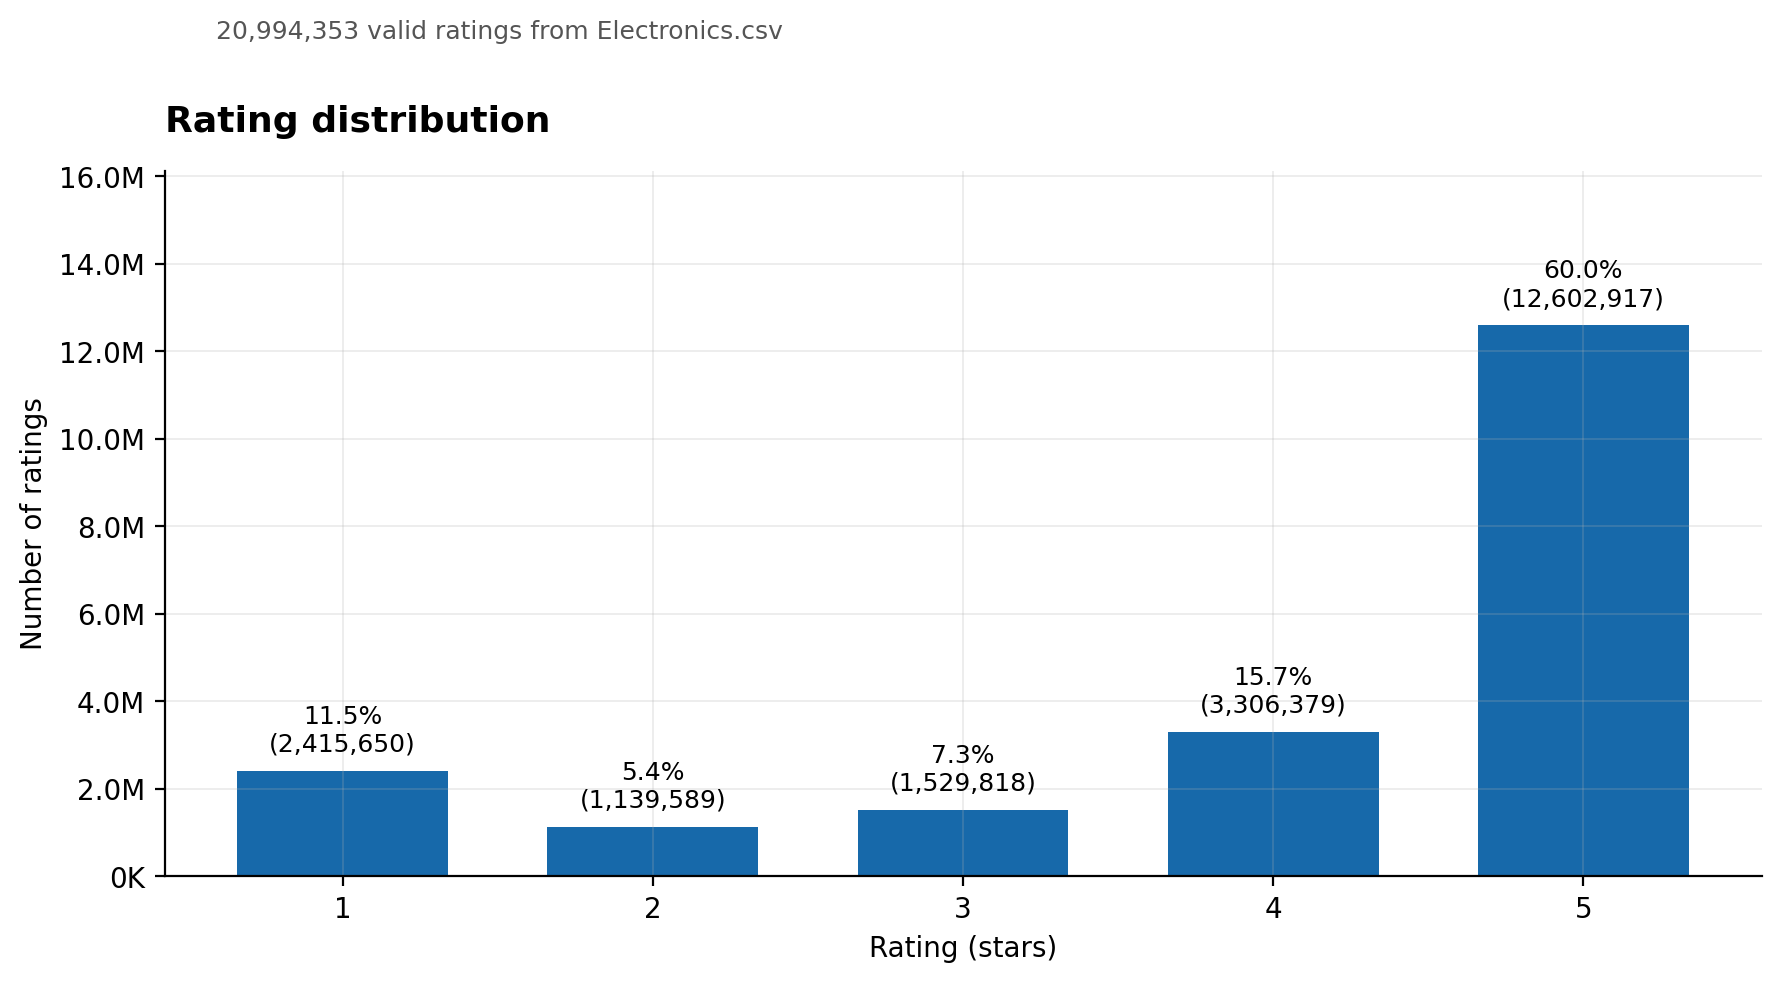

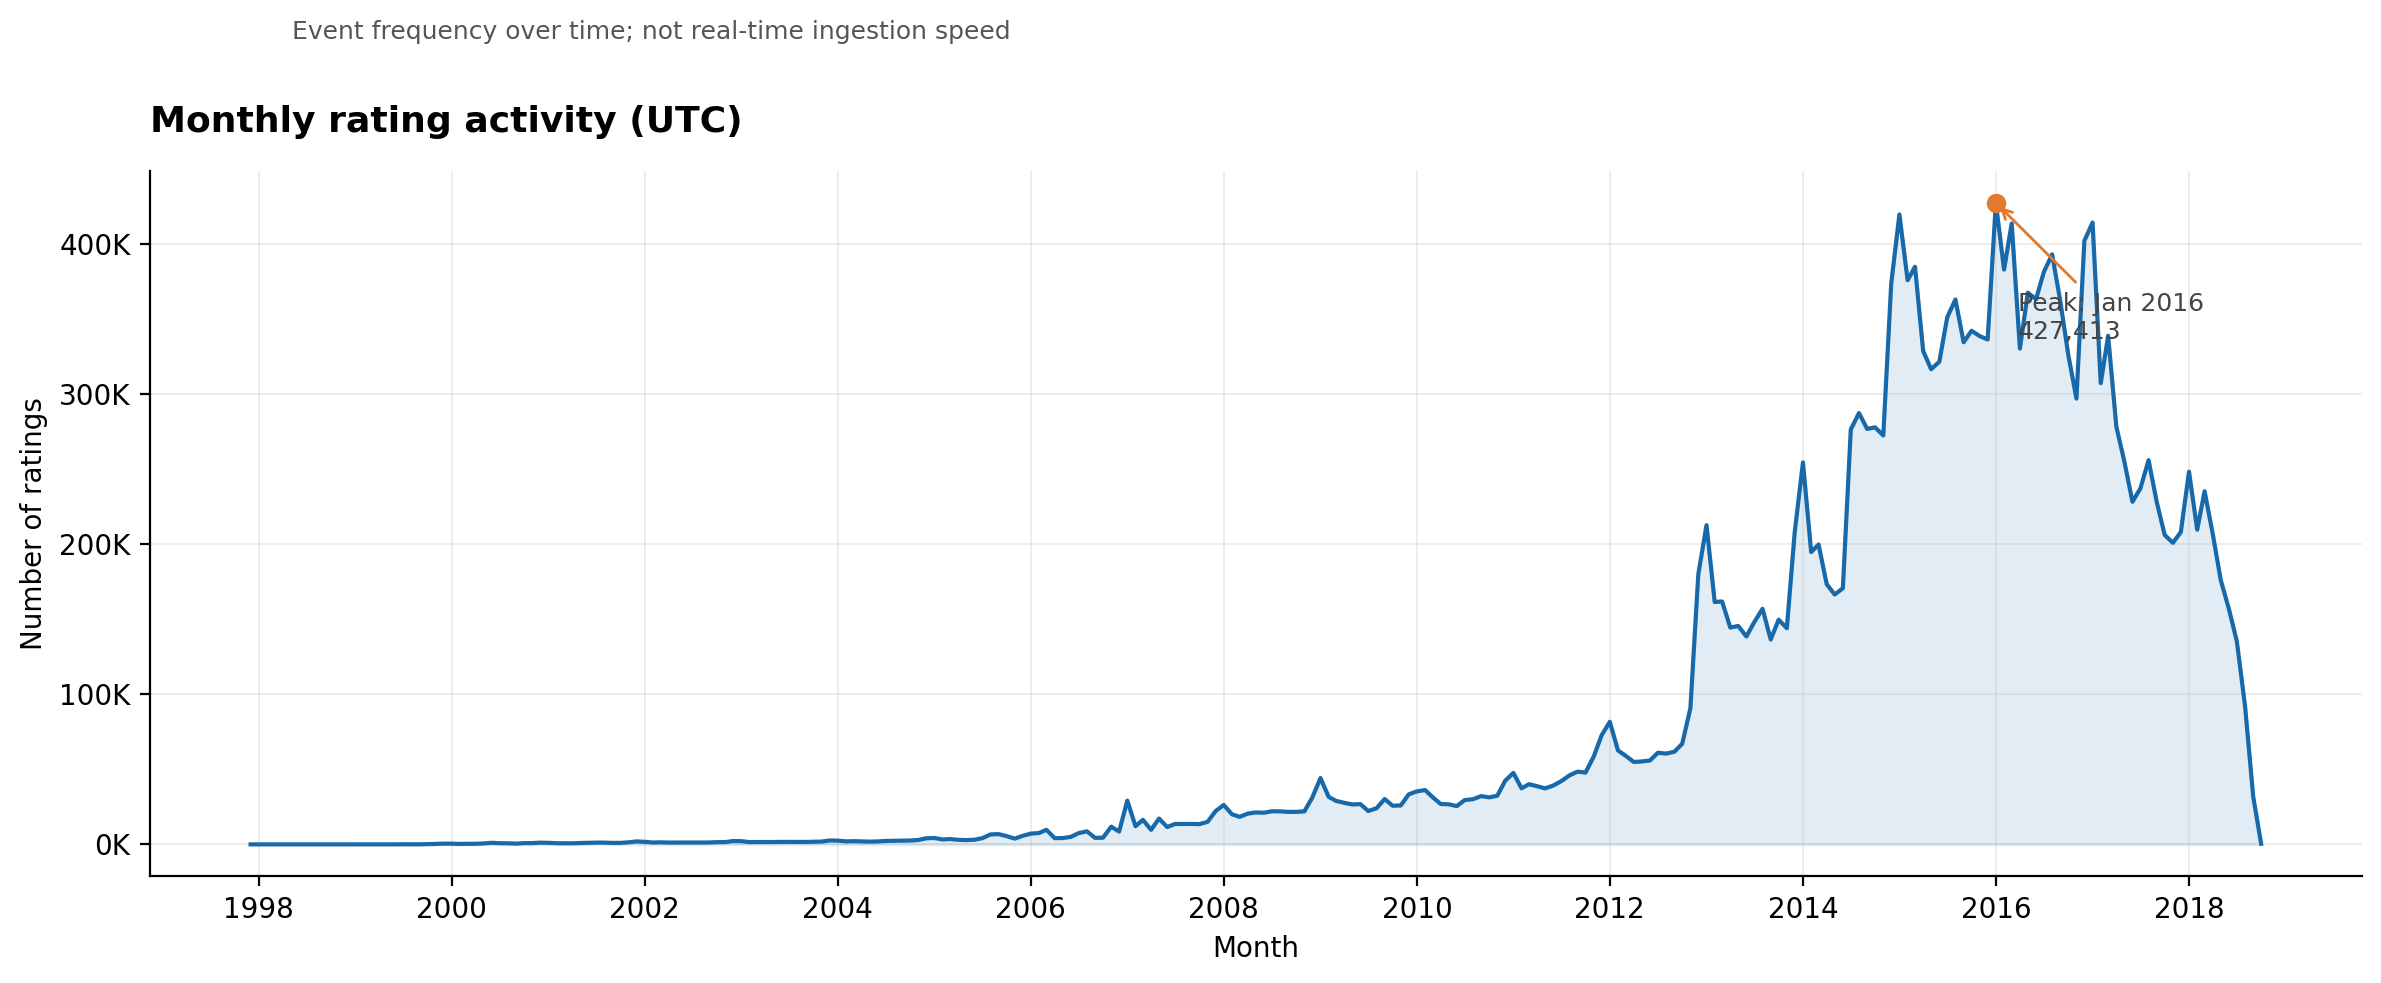

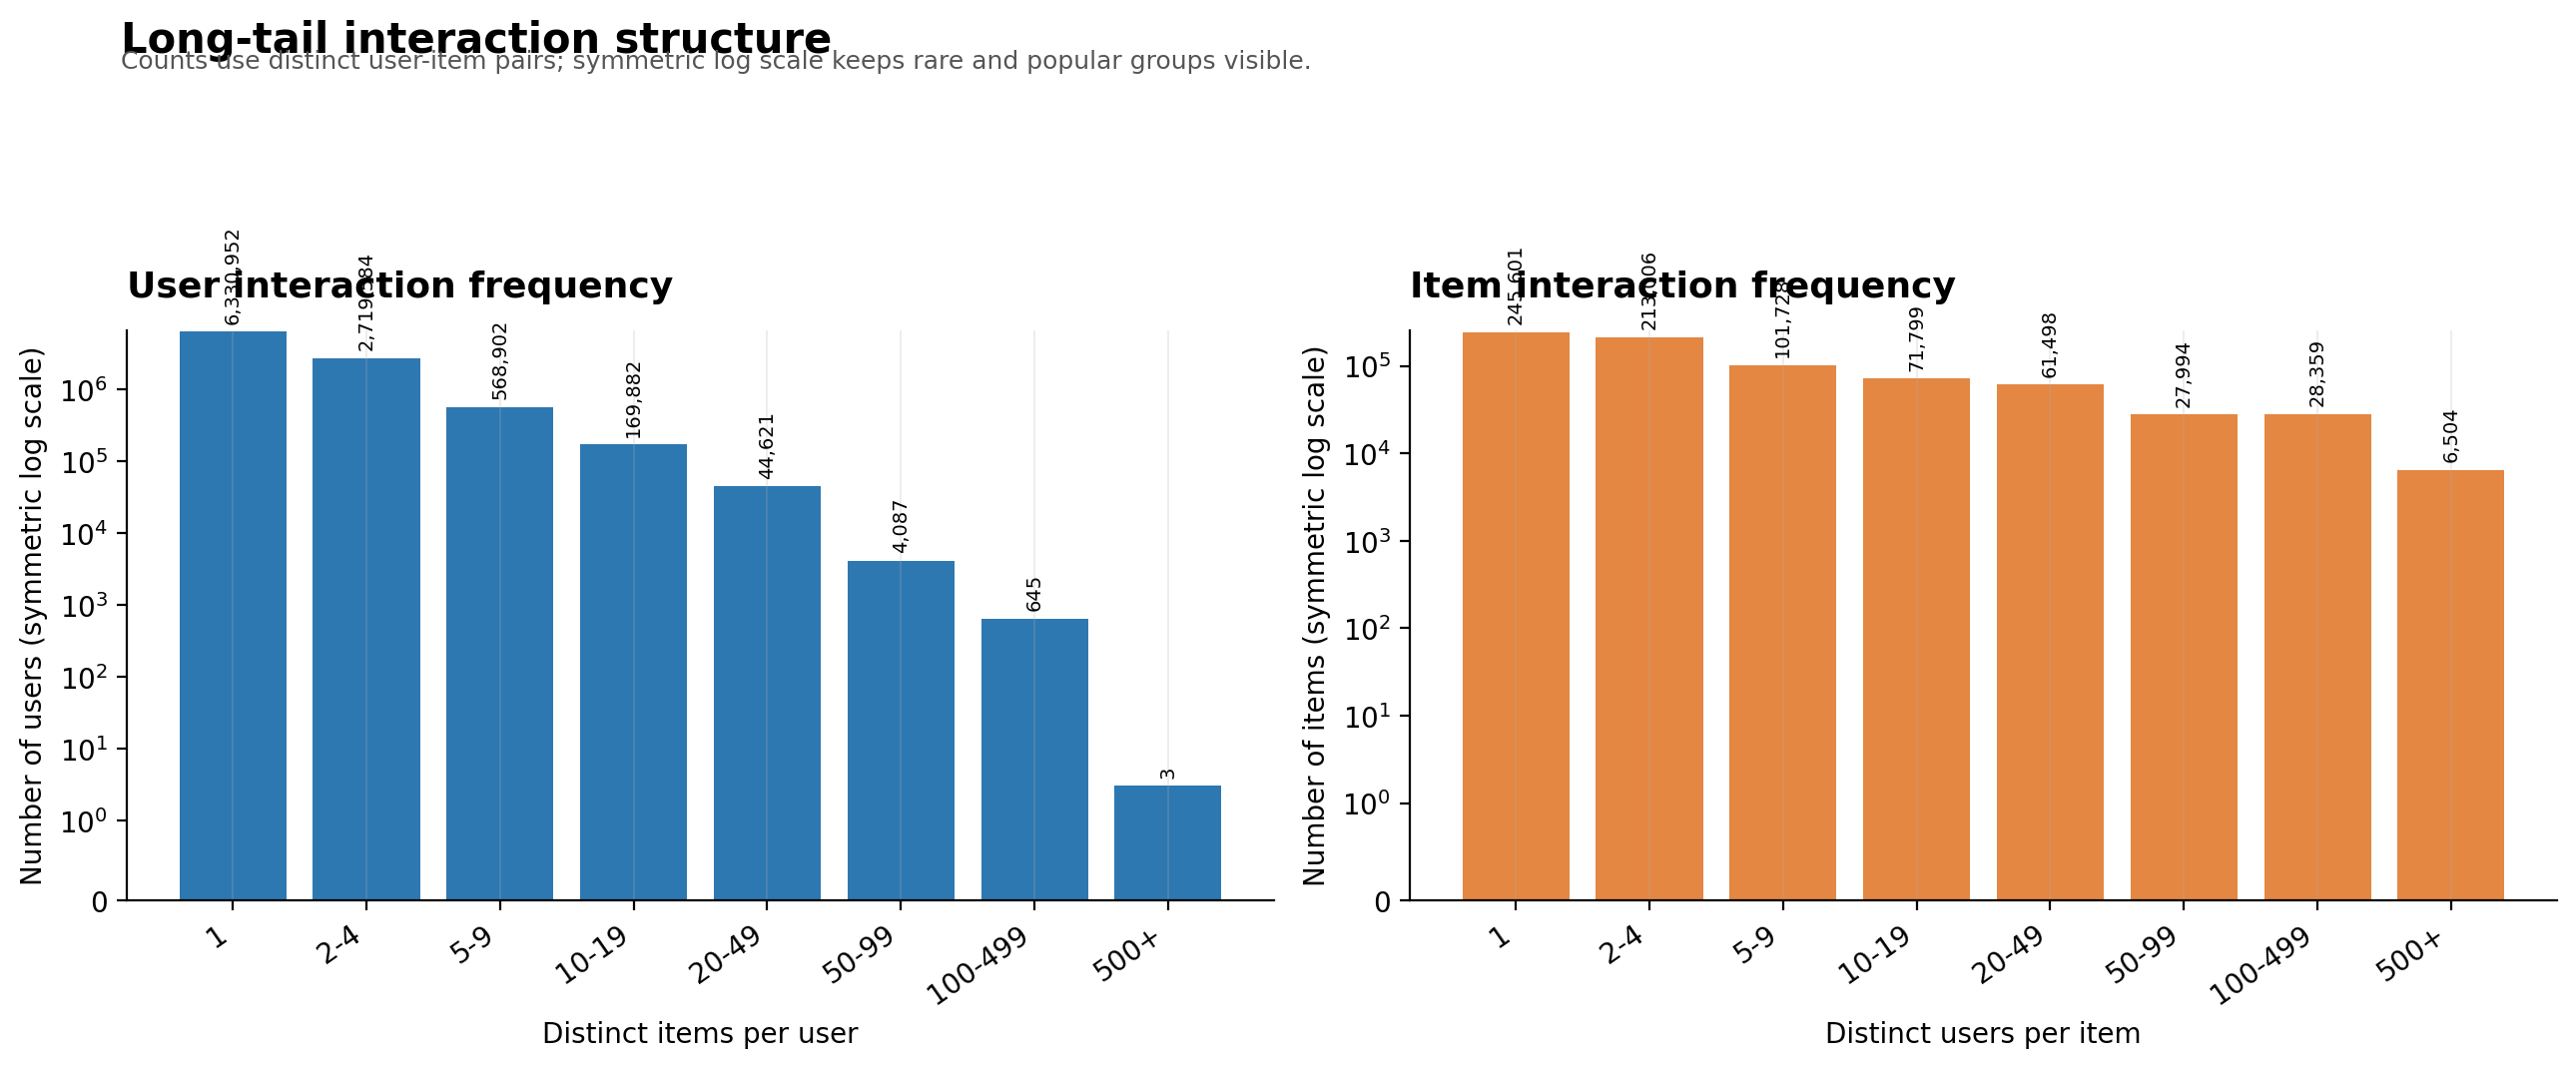

# EDA ? Amazon Electronics Ratings + Product Metadata

## Input files

- Ratings CSV: `D:\msis406\amazon-electronics-bigdata-recommender\data\raw\Electronics.csv`
- Metadata JSON: `D:\msis406\amazon-electronics-bigdata-recommender\data\raw\meta_Electronics.json\meta_Electronics.json`

Input: `D:\msis406\amazon-electronics-bigdata-recommender\data\raw\Electronics.csv`

- Total parsed rows: 20,994,353
- Valid rows: 20,994,353; invalid rows: 0
- Users: 9,838,676; items: 756,489
- Distinct user–item pairs: 20,553,480
- Sparsity: 99.99972385%
- Exact duplicate excess: 426,262
- Repeated-pair excess (includes exact duplicates): 440,873
- Historical period (UTC): 1997-12-04T00:00:00+00:00 → 2018-10-05T00:00:00+00:00

## Method notes

- Quality flags overlap; do not sum them.
- Blank lines are ignored by Spark CSV.
- No deduplication before rating/time distributions; use valid original rows.
- Sparsity and activity use distinct user-item pairs.
- Historical batch data; timestamps do not establish ingestion velocity.
- Remote/glob input requires input-version and an external file manifest.

## 5V evidence

- **Volume:** see counts above; local file bytes = 876247561. Compressed file size, if applicable, differs from decoded size.
- **Variety:** ratings come from `Electronics.csv`; product fields and join coverage come from `meta_Electronics.json`/`.gz`.
- **Velocity:** `monthly_activity.csv` and `figures/time_activity.png` show historical event frequency, not real-time ingestion speed.
- **Veracity:** `ratings_profile.json` gives missing/invalid counts and duplication. Error categories overlap. Excluded rows are not silently repaired.
- **Value:** supports testing Top-10 recommendations using Popularity and ALS; EDA does not prove recommendation quality.

## Interpretation

Sparsity = 1 − distinct(user,item) / (distinct users × distinct items). A large user–item matrix can be sparse even when the row count is large. Inspect the single-interaction entity counts and activity plots before designing evaluation.

Rating/time plots use all valid rows. Interaction histograms count distinct counterpart IDs, so duplicate ratings cannot inflate these histograms. No activity threshold is applied. No train/test split is created by this EDA; any later model preprocessing must fit its rules on training data only.

All sanity checks: True. Valid-row sample is sorted, deterministic, and not statistically representative. Inspect it against the source manually.


In [27]:
for filename in ['rating_distribution.png', 'time_activity.png', 'interaction_hist.png']:
    display(Image(filename=str(out / 'figures' / filename)))
display(Markdown((out / 'eda_summary.md').read_text(encoding='utf-8')))


## 21. Cách diễn giải và giới hạn

- **Độ thưa** = 1 − số cặp user–item duy nhất / (số user × số item). Không dùng số dòng thô khi có cặp lặp.
- Các cờ lỗi có thể chồng lấn, không cộng để ra tổng dòng lỗi. Dòng trắng được Spark bỏ qua; total là số bản ghi Spark đọc được.
- Exact duplicate được xác định sau trim ID/cast số; repeated-pair excess đã bao gồm exact duplicates, không cộng hai chỉ số.
- Rating/time distributions dùng mọi dòng hợp lệ, chưa loại trùng; histogram tương tác và độ thưa dùng cặp duy nhất.
- Sample hợp lệ được sắp xếp cố định để đối chiếu thủ công, không phải sample đại diện. Quantile hoạt động là xấp xỉ với sai số hạng tương đối 0,001; các phép distinct/count là chính xác.
- Không lọc user/item theo ngưỡng hoạt động ở EDA. Khi huấn luyện, xác định quy tắc lọc từ train để tránh leakage.
- Dữ liệu lịch sử không chứng minh realtime/ingest velocity. Chỉ có CSV 4 cột nên không thể phân tích nội dung review, category, brand hoặc sentiment.
- `code_sha256` trong JSON là `null` cho bản notebook; hãy lưu notebook cùng kết quả để truy vết code. SHA256 của CSV vẫn có đầy đủ.
- Thời lượng EDA tính từ bước 4, gồm thời gian chờ giữa các cell nếu chạy thủ công; **không dùng làm benchmark hiệu năng**. Muốn đo gần thời gian xử lý, restart kernel và Run All.

Nếu sửa đường dẫn hoặc logic, nên restart kernel rồi Run All để tránh dùng trạng thái cũ. Chỉ chạy cell dọn bộ nhớ dưới đây sau khi đã xem và lưu kết quả.


In [28]:
# Kết thúc phiên Spark và giải phóng cache.
spark.stop()
print('Đã lưu kết quả tại:', OUTPUT_DIR.resolve())


Đã lưu kết quả tại: D:\msis406\amazon-electronics-bigdata-recommender\outputs\reports\Electronics
